In [85]:
#options: cc200, dosenbach160, aal
p_ROI = "cc200"
p_fold = 10
p_center = "Stanford"
p_mode = "whole"
p_augmentation = False
p_Method = "ASD-DiagNet"
num_repitition = 5
USE_THRESHOLD = True
lamda_fair = 0.5

In [60]:
parameter_list = [p_ROI,p_fold,p_center,p_mode,p_augmentation,p_Method]
print("*****List of patameters****")
print("ROI atlas: ",p_ROI)
print("per Center or whole: ",p_mode)
if p_mode == 'percenter':
    print("Center's name: ",p_center)
print("Method's name: ",p_Method)
if p_Method == "ASD-DiagNet":
    print("Augmentation: ",p_augmentation)


*****List of patameters****
ROI atlas:  cc200
per Center or whole:  whole
Method's name:  ASD-DiagNet
Augmentation:  False


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from functools import reduce
from sklearn.impute import SimpleImputer
import time
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch
import pyprind
import sys
import pickle
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import KFold, StratifiedKFold
import torch.optim as optim
from sklearn.metrics import confusion_matrix
from scipy import stats
from sklearn import tree
import functools
import numpy.ma as ma # for masked arrays
import pyprind
import random
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

if USE_THRESHOLD:
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import roc_curve, accuracy_score
    import matplotlib.pyplot as plt

In [62]:
# Check which Python environment is running
import sys
print(sys.executable)

print("GPU CHECK")

# Check CUDA availability
cuda_available = torch.cuda.is_available()
print("CUDA available:", cuda_available)

# Select device
device = torch.device("cuda" if cuda_available else "cpu")
print("Using device:", device)

if cuda_available:
    # GPU information
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

    # Memory information
    print("Memory allocated:", torch.cuda.memory_allocated(0))
    print("Memory reserved:", torch.cuda.memory_reserved(0))

/disk/dragon-storage/homes/apali007/projects/ASD-DiagNet/venv/bin/python
GPU CHECK
CUDA available: True
Using device: cuda
GPU name: NVIDIA RTX A6000
GPU count: 1
Memory allocated: 594137088
Memory reserved: 1199570944


## Import the phenotypic / summary spreadsheet

In [63]:
df_pheno = pd.read_csv('./data/phenotypes/Phenotypic_V1_0b_preprocessed1.csv')

print("Rows, Cols:", df_pheno.shape)
print("Columns:", list(df_pheno.columns))
print(df_pheno['FILE_ID'].head(10))

Rows, Cols: (1112, 106)
Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'SUB_ID', 'X', 'subject', 'SITE_ID', 'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN', 'SEX', 'HANDEDNESS_CATEGORY', 'HANDEDNESS_SCORES', 'FIQ', 'VIQ', 'PIQ', 'FIQ_TEST_TYPE', 'VIQ_TEST_TYPE', 'PIQ_TEST_TYPE', 'ADI_R_SOCIAL_TOTAL_A', 'ADI_R_VERBAL_TOTAL_BV', 'ADI_RRB_TOTAL_C', 'ADI_R_ONSET_TOTAL_D', 'ADI_R_RSRCH_RELIABLE', 'ADOS_MODULE', 'ADOS_TOTAL', 'ADOS_COMM', 'ADOS_SOCIAL', 'ADOS_STEREO_BEHAV', 'ADOS_RSRCH_RELIABLE', 'ADOS_GOTHAM_SOCAFFECT', 'ADOS_GOTHAM_RRB', 'ADOS_GOTHAM_TOTAL', 'ADOS_GOTHAM_SEVERITY', 'SRS_VERSION', 'SRS_RAW_TOTAL', 'SRS_AWARENESS', 'SRS_COGNITION', 'SRS_COMMUNICATION', 'SRS_MOTIVATION', 'SRS_MANNERISMS', 'SCQ_TOTAL', 'AQ_TOTAL', 'COMORBIDITY', 'CURRENT_MED_STATUS', 'MEDICATION_NAME', 'OFF_STIMULANTS_AT_SCAN', 'VINELAND_RECEPTIVE_V_SCALED', 'VINELAND_EXPRESSIVE_V_SCALED', 'VINELAND_WRITTEN_V_SCALED', 'VINELAND_COMMUNICATION_STANDARD', 'VINELAND_PERSONAL_V_SCALED', 'VINELAND_DOMESTIC_V_SCALED', 'VI

## Import the preprocessed ABIDE ROI time-series (CC200, C-PAC) data

In [64]:
data_main_path = './data/functionals/cpac/filt_global/rois_' + p_ROI 
flist = [
    f for f in os.listdir(data_main_path)
    if f.endswith('.1D')
] 
print(len(flist))
print(flist[:10])

1035
['Leuven_1_0050703_rois_cc200.1D', 'UCLA_2_0051292_rois_cc200.1D', 'UCLA_1_0051217_rois_cc200.1D', 'NYU_0051064_rois_cc200.1D', 'OHSU_0050164_rois_cc200.1D', 'UM_1_0050345_rois_cc200.1D', 'SBL_0051573_rois_cc200.1D', 'USM_0050467_rois_cc200.1D', 'KKI_0050795_rois_cc200.1D', 'Leuven_1_0050696_rois_cc200.1D']


## Combine and filter dataset

In [65]:
def get_key(filename):
    f_split = filename.split('_')
    if f_split[3] == 'rois':
        key = '_'.join(f_split[0:3]) 
    else:
        key = '_'.join(f_split[0:2])
    return key

flist_norm = [get_key(f) for f in flist]

df_fil = df_pheno[df_pheno['FILE_ID'].isin(flist_norm)].copy()

print("Filtered dataset size:", len(df_fil))

Filtered dataset size: 1035


## Label distribution

In [66]:
total = len(df_fil)

dx_counts = df_fil['DX_GROUP'].value_counts()

asd_count = dx_counts[1]
control_count = dx_counts[2]

print("Total subjects:", total)
print("ASD (1) count:", asd_count)
print("Control (2) count:", control_count)

print("\nASD (1) percentage: {:.2f}%".format(100 * asd_count / total))
print("Control (2) percentage: {:.2f}%".format(100 * control_count / total))

Total subjects: 1035
ASD (1) count: 505
Control (2) count: 530

ASD (1) percentage: 48.79%
Control (2) percentage: 51.21%


## Sex distribution

In [67]:
sex_counts = df_fil['SEX'].value_counts()

male_count = sex_counts[1]
female_count = sex_counts[2]

print("\nMale (1) count:", male_count)
print("Female (2) count:", female_count)

print("\nMale (1) percentage: {:.2f}%".format(100 * male_count / total))
print("Female (2) percentage: {:.2f}%".format(100 * female_count / total))


Male (1) count: 878
Female (2) count: 157

Male (1) percentage: 84.83%
Female (2) percentage: 15.17%


## Sex distribution within each diagnosis

In [68]:
cross_counts = pd.crosstab(df_fil['SEX'], df_fil['DX_GROUP'])
print(cross_counts)

cross_norm_diag = pd.crosstab(df_fil['SEX'],
                             df_fil['DX_GROUP'],
                             normalize='columns'
                             )
print("\nSex distribution within each diagnosis")
print(cross_norm_diag)

DX_GROUP    1    2
SEX               
1         443  435
2          62   95

Sex distribution within each diagnosis
DX_GROUP         1         2
SEX                         
1         0.877228  0.820755
2         0.122772  0.179245


## Base rates per sex

In [69]:
base_rates = pd.crosstab(df_fil['SEX'],
                        df_fil['DX_GROUP'],
                        normalize='index')

print("Base Rates (P(DX_GROUP | SEX))")
print(base_rates)

Base Rates (P(DX_GROUP | SEX))
DX_GROUP         1         2
SEX                         
1         0.504556  0.495444
2         0.394904  0.605096


## Data Preprocessing and Attribute Mapping 

In [70]:
for f in range(len(flist)):
    flist[f] = get_key(flist[f])

df_fil.DX_GROUP = df_fil.DX_GROUP.map({1: 1, 2:0})
# 1 -> ASD, 0 -> Control
df_fil.SEX = df_fil.SEX.map({1: 1, 2:0})
# 1 -> Male, 0 -> Female
print(len(df_fil))

1035


In [71]:
labels = {}
sensitive_attrs = {}
for row in df_fil.iterrows():
    file_id = row[1]['FILE_ID']
    y_label = row[1]['DX_GROUP']
    sensitive_attr = row[1]['SEX']
    if file_id == 'no_filename':
        continue
    assert(file_id not in labels)
    labels[file_id] = y_label
    assert(file_id not in sensitive_attrs)
    sensitive_attrs[file_id] = sensitive_attr

print("Label counts:")
print(pd.Series(labels).value_counts(dropna=False))

print("\nSensitive counts:")
print(pd.Series(sensitive_attrs).value_counts(dropna=False))

Label counts:
0    530
1    505
Name: count, dtype: int64

Sensitive counts:
1    878
0    157
Name: count, dtype: int64


## Helper functions for computing correlations

In [73]:
# Returns 0 (Control) or 1 (ASD)
def get_label(filename):
    assert (filename in labels)
    return labels[filename]

# Returns 0 (Female) or 1 (Male)
def get_sensitive(filename):
    assert (filename in sensitive_attrs)
    return sensitive_attrs[filename]


# loads a subject’s ROI fMRI time series, computes the Pearson correlation matrix across regions, and returns the unique pairwise correlations as a 1D feature vector.
def get_corr_data(filename):
    #print(filename)
    for file in os.listdir(data_main_path):
        if file.startswith(filename):
            df = pd.read_csv(os.path.join(data_main_path, file), sep='\t')
            # df contains fmri time series data (number of time points (T) * number of ROIs (R))
            
    with np.errstate(invalid="ignore"):
        #cleaning the correlation matrix
        corr = np.nan_to_num(np.corrcoef(df.T)) #corr contains the 200 * 200 (subjects * subjects) correlation matrix

        # creates a lower-triangular matrix (excluding diagonal)
        mask = np.invert(np.tri(corr.shape[0], k=-1, dtype=bool))

        # Mask everything except the strict lower triangle
        m = ma.masked_where(mask == 1, mask)

        # Flattens, Removes masked values, Returns a 1D NumPy array
        return ma.masked_where(m, corr).compressed()

    # loads a subject’s ROI fMRI time series, computes the Pearson correlation matrix across regions and returns it
def get_corr_matrix(filename):
    for file in os.listdir(data_main_path):
        if file.startswith(filename):
            df = pd.read_csv(os.path.join(data_main_path, file), sep='\t')
    with np.errstate(invalid="ignore"):
        corr = np.nan_to_num(np.corrcoef(df.T))
        return corr

def confusion(g_turth,predictions):
    tn, fp, fn, tp = confusion_matrix(g_turth,predictions).ravel()
    accuracy = (tp+tn)/(tp+fp+tn+fn)
    sensitivity = (tp)/(tp+fn)
    specificty = (tn)/(tn+fp)
    return accuracy,sensitivity,specificty

def get_regs(samplesnames,regnum):
    datas = []
    for sn in samplesnames:
        datas.append(all_corr[sn][0])
    datas = np.array(datas)
    avg=[]
    for ie in range(datas.shape[1]):
        avg.append(np.mean(datas[:,ie]))
    avg=np.array(avg)
    highs=avg.argsort()[-regnum:][::-1]
    lows=avg.argsort()[:regnum][::-1]
    regions=np.concatenate((highs,lows),axis=0)
    return regions


## Computing correlations and storing it in a file

In [74]:
if not os.path.exists('./correlations_file'+p_ROI+'_fairness'+'.pkl'):
    pbar=pyprind.ProgBar(len(flist))
    all_corr = {}
    for f in flist:
      
        lab = get_label(f)
        sensitive = get_sensitive(f)
        all_corr[f] = (get_corr_data(f), lab, sensitive)
        pbar.update()

    print('Corr-computations finished')

    pickle.dump(all_corr, open('./correlations_file'+p_ROI+'_fairness'+'.pkl', 'wb'))
    print('Saving to file finished')

else:
    all_corr = pickle.load(open('./correlations_file'+p_ROI+'_fairness'+'.pkl', 'rb'))

print("Number of subjects:", len(all_corr))
print("Tuple length per subject:", len(all_corr[flist[0]]))

Number of subjects: 1035
Tuple length per subject: 3


##  Evaluating Sex attribute encoded in correlations features using logistic regression

In [75]:
X_list = []
S_list = []

for fname in all_corr:
    feat, _, sex = all_corr[fname]
    X_list.append(feat)
    S_list.append(sex)

X = np.array(X_list)   # shape: N × D
S = np.array(S_list)   # shape: N

In [17]:
print(X.shape)
print(S.shape)

(1035, 19900)
(1035,)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000))
])

scores = cross_val_score(
    clf,
    X,
    S,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Sex prediction accuracy per fold:", scores)
print("Mean accuracy:", scores.mean())

Sex prediction accuracy per fold: [0.87439614 0.84057971 0.8647343  0.85507246 0.85990338]
Mean accuracy: 0.8589371980676329


## Computing eigenvalues and eigenvector

In [18]:
if p_Method=="ASD-DiagNet":
    eig_data = {}
    pbar = pyprind.ProgBar(len(flist))
    for f in flist:  
        d = get_corr_matrix(f)
        eig_vals, eig_vecs = np.linalg.eig(d)

        for ev in eig_vecs.T:
            np.testing.assert_array_almost_equal(1.0, np.linalg.norm(ev))

        sum_eigvals = np.sum(np.abs(eig_vals))
        # Make a list of (eigenvalue, eigenvector, norm_eigval) tuples
        eig_pairs = [(np.abs(eig_vals[i]), eig_vecs[:,i], np.abs(eig_vals[i])/sum_eigvals)
                     for i in range(len(eig_vals))]

        # Sort the (eigenvalue, eigenvector) tuples from high to low
        eig_pairs.sort(key=lambda x: x[0], reverse=True)

        eig_data[f] = {'eigvals':np.array([ep[0] for ep in eig_pairs]),
                       'norm-eigvals':np.array([ep[2] for ep in eig_pairs]),
                       'eigvecs':[ep[1] for ep in eig_pairs]}
        pbar.update()

## Calculating Eros similarity

In [76]:
def norm_weights(sub_flist):
    num_dim = len(eig_data[flist[0]]['eigvals'])
    norm_weights = np.zeros(shape=num_dim)
    for f in sub_flist:
        norm_weights += eig_data[f]['norm-eigvals'] 
    return norm_weights

def cal_similarity(d1, d2, weights, lim=None):
    res = 0.0
    if lim is None:
        weights_arr = weights.copy()
    else:
        weights_arr = weights[:lim].copy()
        weights_arr /= np.sum(weights_arr)
    for i,w in enumerate(weights_arr):
        res += w*np.inner(d1[i], d2[i])
    return res

## Defining dataset class

In [77]:
class CC200Dataset(Dataset):
    def __init__(self, pkl_filename=None, data=None, samples_list=None, 
                 augmentation=False, aug_factor=1, num_neighbs=5,
                 eig_data=None, similarity_fn=None, verbose=False,regs=None):
        self.regs=regs
        if pkl_filename is not None:
            if verbose:
                print ('Loading ..!', end=' ')
            self.data = pickle.load(open(pkl_filename, 'rb'))
        elif data is not None:
            self.data = data.copy()
            
        else:
            sys.stderr.write('Eigther PKL file or data is needed!')
            return 

        #if verbose:
        #    print ('Preprocess..!', end='  ')
        if samples_list is None:
            self.flist = [f for f in self.data]
        else:
            self.flist = [f for f in samples_list]
        self.labels = np.array([self.data[f][1] for f in self.flist])
        
        current_flist = np.array(self.flist.copy())
        current_lab0_flist = current_flist[self.labels == 0]
        current_lab1_flist = current_flist[self.labels == 1]
        #if verbose:
        #    print(' Num Positive : ', len(current_lab1_flist), end=' ')
        #    print(' Num Negative : ', len(current_lab0_flist), end=' ')
        
        
        if augmentation:
            self.num_data = aug_factor * len(self.flist)
            self.neighbors = {}
            pbar = pyprind.ProgBar(len(self.flist))
            weights = norm_weights(samples_list)#??
            for f in self.flist:
                label = self.data[f][1]
                candidates = (set(current_lab0_flist) if label == 0 else set(current_lab1_flist))
                candidates.remove(f)
                eig_f = eig_data[f]['eigvecs']
                sim_list = []
                for cand in candidates:
                    eig_cand = eig_data[cand]['eigvecs']
                    sim = similarity_fn(eig_f, eig_cand,weights)
                    sim_list.append((sim, cand))
                sim_list.sort(key=lambda x: x[0], reverse=True)
                self.neighbors[f] = [item[1] for item in sim_list[:num_neighbs]]#list(candidates)#[item[1] for item in sim_list[:num_neighbs]]
        
        else:
            self.num_data = len(self.flist)

        
    def __getitem__(self, index):
         # ---------- Normal Sample ----------
        if index < len(self.flist):
            fname = self.flist[index]
            data = self.data[fname][0].copy() #get_corr_data(fname, mode=cal_mode)    
            data = data[self.regs].copy()
            label = (self.labels[index],)
            sensitive = self.data[fname][2]
            return (
                torch.FloatTensor(data), torch.FloatTensor(label), torch.LongTensor([sensitive])
            )
        else:
            # ---------- Augmented Sample ----------
            f1 = self.flist[index % len(self.flist)]
            d1, y1, s1 = self.data[f1]
            d1=d1[self.regs]
            f2 = np.random.choice(self.neighbors[f1])
            d2, y2, _ = self.data[f2]
            d2=d2[self.regs]
            assert y1 == y2
            r = np.random.uniform(low=0, high=1)
            label = (y1,)
            data = r*d1 + (1-r)*d2
            return (torch.FloatTensor(data), torch.FloatTensor(label), torch.LongTensor([s1]))

    def __len__(self):
        return self.num_data

## Definig data loader function

In [78]:
def get_loader(pkl_filename=None, data=None, samples_list=None,
               batch_size=64, 
               num_workers=1, mode='train',
               *, augmentation=False, aug_factor=1, num_neighbs=5,
                 eig_data=None, similarity_fn=None, verbose=False,regions=None):
    """Build and return data loader."""
    if mode == 'train':
        shuffle = True
    else:
        shuffle = False
        augmentation=False

    dataset = CC200Dataset(pkl_filename=pkl_filename, data=data, samples_list=samples_list,
                           augmentation=augmentation, aug_factor=aug_factor, 
                           eig_data=eig_data, similarity_fn=similarity_fn, verbose=verbose,regs=regions)

    data_loader = DataLoader(dataset,
                             batch_size=batch_size,
                             shuffle=shuffle,
                             num_workers=num_workers)
  
    return data_loader

## Defining Autoencoder class

In [79]:
class MTAutoEncoder(nn.Module):
    def __init__(self, num_inputs=990, 
                 num_latent=200, tied=True,
                 num_classes=2, use_dropout=False):
        super(MTAutoEncoder, self).__init__()
        self.tied = tied
        self.num_latent = num_latent
        
        self.fc_encoder = nn.Linear(num_inputs, num_latent)
    
        if not tied:
            self.fc_decoder = nn.Linear(num_latent, num_inputs)
         
        self.fc_encoder = nn.Linear(num_inputs, num_latent)
        
        if use_dropout:
            self.classifier = nn.Sequential (
                nn.Dropout(p=0.5),
                nn.Linear(self.num_latent, 1),
                
            )
        else:
            self.classifier = nn.Sequential (
                nn.Linear(self.num_latent, 1),
            )
            
         
    def forward(self, x, eval_classifier=False, return_latent=False):
        z = self.fc_encoder(x)
        z = torch.tanh(z)
        if eval_classifier:
            x_logit = self.classifier(z)
        else:
            x_logit = None
        
        if self.tied:
            x_rec = F.linear(z, self.fc_encoder.weight.t())
        else:
            x_rec = self.fc_decoder(z)
            
        if return_latent:
            return x_rec, x_logit, z
        
        return x_rec, x_logit

mtae = MTAutoEncoder()

mtae

# latent extraction function
def extract_latents(model, loader):
    model.eval()

    Z_all = []
    S_all = []

    with torch.no_grad():
        for batch_x, _, batch_sensitive in loader:
            data = batch_x.to(device)
            _, _, z = model(data, eval_classifier=True, return_latent=True)
            Z_all.append(z.cpu().numpy())
            S_all.append(batch_sensitive.numpy())

    Z = np.vstack(Z_all)
    S = np.concatenate(S_all).flatten()

    return Z, S

## Compute Fairness (TPR and FPR gaps)

In [84]:
def compute_fairness_gaps(y_true, y_pred, sensitive):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    sensitive = np.array(sensitive)

    group_metrics = {}

    for g in [0,1]:

        mask_sens = (sensitive == g)

        if mask_sens.sum() == 0:
            # if groups are not present
            group_metrics[g] = (np.nan,np.nan, np.nan)
            continue

        yt = y_true[mask_sens]
        yp = y_pred[mask_sens]

        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0,1]).ravel()

        tpr = tp / (tp + fn) if (tp + fn)>0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn)>0 else np.nan

        dp = np.mean(yp) if len(yp)>0 else np.nan

        group_metrics[g] = (tpr, fpr, dp)

    # equal opportunity (TPR gap) and equalized odds (TPR and FPR gap)
    if not (np.isnan(group_metrics[1][0]) or np.isnan(group_metrics[0][0])):
        # absolute difference
        delta_tpr = abs(group_metrics[1][0] - group_metrics[0][0])
    else:
        delta_tpr = np.nan

    if not (np.isnan(group_metrics[1][1]) or np.isnan(group_metrics[0][1])):
        delta_fpr = abs(group_metrics[1][1] - group_metrics[0][1])
    else:
       delta_fpr = np.nan 

    # demographic parity gap
    if not (np.isnan(group_metrics[1][2]) or np.isnan(group_metrics[0][2])):
        delta_dp = abs(group_metrics[1][2] - group_metrics[0][2])
    else:
        delta_dp = np.nan

    return delta_tpr, delta_fpr, delta_dp

# def learn_eo_thresholds(y_true, scores, sensitive):
    
#     y_true = np.array(y_true)
#     scores = np.array(scores).flatten()
#     sensitive = np.array(sensitive)

#     mask0 = (sensitive == 0)
#     mask1 = (sensitive == 1)

#     y0, s0 = y_true[mask0], scores[mask0]
#     y1, s1 = y_true[mask1], scores[mask1]

#     fpr0, tpr0, thr0 = roc_curve(y0, s0)
#     fpr1, tpr1, thr1 = roc_curve(y1, s1)

#     best = None
#     candidate_tprs = np.unique(np.concatenate([tpr0,tpr1]))

#     for u in candidate_tprs:

#         # find thresholds closest to target TPR
#         idx0 = np.argmin(np.abs(tpr0 - u))
#         idx1 = np.argmin(np.abs(tpr1 - u))

#         t0 = thr0[idx0]
#         t1 = thr1[idx1]

#         tpr0_closest = tpr0[idx0]
#         tpr1_closest = tpr1[idx1]

#         preds = np.zeros_like(scores)

#         preds[mask0] = (s0 >= t0).astype(int)
#         preds[mask1] = (s1 >= t1).astype(int)

#         acc = accuracy_score(y_true, preds)

#         def get_tpr(y,p):
#             tn, fp, fn, tp = confusion_matrix(y,p, labels=[0,1]).ravel()
#             return tp/(tp+fn) if (tp+fn)>0 else 0
        
#         tpr0_val = get_tpr(y0, preds[mask0])
#         tpr1_val = get_tpr(y1, preds[mask1])

#         gap = abs(tpr0_val - tpr1_val)

#         score = acc - lamda_fair * gap

#         if best is None or score > best["score"]:
#             best = {
#                 "t0": t0,
#                 "t1": t1,
#                 "gap": gap,
#                 "acc": acc,
#                 "score": score,
#                 "u" : u,
#                 "tpr0_closest": tpr0_closest,
#                 "tpr1_closest": tpr1_closest
#             }

#     return best


# def learn_eo_thresholds(y_true, scores, sensitive):
    
#     y_true = np.array(y_true)
#     scores = np.array(scores).flatten()
#     sensitive = np.array(sensitive)

#     mask0 = (sensitive == 0)
#     mask1 = (sensitive == 1)

#     y0, s0 = y_true[mask0], scores[mask0]
#     y1, s1 = y_true[mask1], scores[mask1]

#     _, _, thr0 = roc_curve(y0, s0)
#     _, _, thr1 = roc_curve(y1, s1)

#     best = None

#     for t0 in thr0[1:-1]:
#         for t1 in thr1[1:-1]:

#             preds = np.zeros_like(scores)

#             preds[mask0] = (s0 >= t0).astype(int)
#             preds[mask1] = (s1 >= t1).astype(int)

#             def get_tpr(y,p):
#                 tn, fp, fn, tp = confusion_matrix(y,p, labels=[0,1]).ravel()
#                 return tp/(tp+fn) if (tp+fn)>0 else 0
            
#             tpr0_val = get_tpr(y0, preds[mask0])
#             tpr1_val = get_tpr(y1, preds[mask1])

#             gap = abs(tpr0_val - tpr1_val)

#             acc = accuracy_score(y_true, preds)

#             score = acc - lamda_fair * gap

#             if best is None or score > best["score"]:
#                 best = {
#                     "t0": t0,
#                     "t1": t1,
#                     "gap": gap,
#                     "acc": acc,
#                     "score": score,
#                     "tpr0": tpr0_val,
#                     "tpr1": tpr1_val
#                 }

#     return best

# # most faithful
# def learn_eo_thresholds(y_true, scores, sensitive):
    
#     y_true = np.array(y_true)
#     scores = np.array(scores).flatten()
#     sensitive = np.array(sensitive)

#     mask0 = (sensitive == 0)
#     mask1 = (sensitive == 1)

#     y0, s0 = y_true[mask0], scores[mask0]
#     y1, s1 = y_true[mask1], scores[mask1]

#     _, tpr0, thr0 = roc_curve(y0, s0)
#     _, tpr1, thr1 = roc_curve(y1, s1)

#     best = None

#     for target_tpr in np.linspace(0,1,200):

#         idx0 = np.argmin(np.abs(tpr0 - target_tpr))
#         idx1 = np.argmin(np.abs(tpr1 - target_tpr))

#         t0 = thr0[idx0]
#         t1 = thr1[idx1]

#         preds = np.zeros_like(scores)

#         preds[mask0] = (s0 >= t0).astype(int)
#         preds[mask1] = (s1 >= t1).astype(int)

#         acc = accuracy_score(y_true, preds)
#         gap = abs(tpr0[idx0] - tpr1[idx1])

#         if best is None or gap < best["gap"] or (gap == best["gap"] and acc > best["acc"]):
#             best = {
#                 "t0": t0,
#                 "t1": t1,
#                 "gap": gap,
#                 "acc": acc,
#             }

#     return best

# # most faithful wth some tolerance
def learn_eo_thresholds(y_true, scores, sensitive):
    
    y_true = np.array(y_true)
    scores = np.array(scores).flatten()
    sensitive = np.array(sensitive)

    mask0 = (sensitive == 0)
    mask1 = (sensitive == 1)

    y0, s0 = y_true[mask0], scores[mask0]
    y1, s1 = y_true[mask1], scores[mask1]

    fpr0, tpr0, thr0 = roc_curve(y0, s0)
    fpr1, tpr1, thr1 = roc_curve(y1, s1)

    print("\n--- Class distribution per group in validation set---")

    print(f"Group 0 (female):")
    print(f"  Total: {len(y0)}")
    print(f"  Positives (Y=1): {(y0==1).sum()}")
    print(f"  Negatives (Y=0): {(y0==0).sum()}")

    print(f"\nGroup 1 (male):")
    print(f"  Total: {len(y1)}")
    print(f"  Positives (Y=1): {(y1==1).sum()}")
    print(f"  Negatives (Y=0): {(y1==0).sum()}")
    
    plotROCcurves(fpr0, tpr0, fpr1, tpr1)

    best = None
    tpr_list = []
    cost_list = []
    tpr0_list = []
    tpr1_list = []

    tpr_max = min(tpr0.max(), tpr1.max())

    for target_tpr in np.linspace(0,tpr_max,200):

        idx0 = np.argmin(np.abs(tpr0 - target_tpr))
        idx1 = np.argmin(np.abs(tpr1 - target_tpr))
        gap = abs(tpr0[idx0] - tpr1[idx1])

        
        if gap > 0.05:
            continue

        t0 = thr0[idx0]
        t1 = thr1[idx1]

        actual_tpr = (tpr0[idx0] +tpr1[idx1]) / 2

        tpr0_val = tpr0[idx0]
        tpr1_val = tpr1[idx1]

        preds = np.zeros_like(scores)

        preds[mask0] = (s0 >= t0).astype(int)
        preds[mask1] = (s1 >= t1).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()

        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan

        if np.isnan(fpr) or np.isnan(fnr):
            continue

        c_fp = 1.0
        c_fn = 1.0

        cost = c_fp * fpr + c_fn * fnr

        acc = accuracy_score(y_true, preds)

        # store values for plot
        tpr_list.append(actual_tpr)
        cost_list.append(cost)
        tpr0_list.append(tpr0_val)
        tpr1_list.append(tpr1_val)
        
        if best is None or cost < best["cost"]:
            best = {
                "t0": t0,
                "t1": t1,
                "gap": gap,
                "cost": cost,
                "actual_tpr": actual_tpr,
                "acc": acc
            }
    
    plotEOcurve(tpr_list, cost_list, tpr0_list, tpr1_list, best)
        
        # if best is None or acc > best["acc"]:
        #     best = {
        #         "t0": t0,
        #         "t1": t1,
        #         "gap": gap,
        #         "acc": acc,
        #     }

    return best


def apply_eo_thresholds(scores, sensitive, t0, t1):

    scores = np.array(scores).flatten()
    sensitive = np.array(sensitive)

    preds = np.zeros_like(scores)

    preds[sensitive==0] = (scores[sensitive == 0] >= t0).astype(int)
    preds[sensitive==1] = (scores[sensitive == 1] >= t1).astype(int)

    return preds

def plotROCcurves(fpr0, tpr0, fpr1, tpr1):
    plt.figure(figsize=(6,6))

    # ROC for both groups
    plt.plot(fpr0, tpr0, label="Group 0 (female)", linewidth=2)
    plt.plot(fpr1, tpr1, label="Group 1 (male)", linewidth=2)

    # Random baseline
    plt.plot([0,1], [0,1], 'k--', label="Random")

    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.title("ROC Curves by Group")
    plt.legend()
    plt.grid(True)

    plt.show()

def plotEOcurve(tpr_list, cost_list,tpr0_list, tpr1_list, best):
    plt.figure(figsize=(6,5))

    # main EO curve
    # plt.plot(cost_list,tpr_list , marker='o', label='EO Cost Curve', linewidth=2)

    plt.plot(cost_list, tpr0_list, '--', label="Female TPR", alpha = 0.7)
    plt.plot(cost_list, tpr1_list, '--', label="Male TPR", alpha = 0.7)


    #Mask optimal point
    if best is not None:
        plt.scatter( best["cost"], best["actual_tpr"], color='red', s=100, label='Optimal EO')

    plt.xlabel("Cost (FPR + FNR)")
    plt.ylabel("Actual TPR")
    plt.title("Equal Opportunity: Cost vs TPR")
    plt.grid(True)
    plt.legend()

    plt.show()


## Defining training and testing functions

In [81]:
from torch import device


def train(model, epoch, train_loader, p_bernoulli=None, mode='both', lam_factor=1.0):
    model.train()
    train_losses = []
    for i,(batch_x,batch_y,batch_sensitive) in enumerate(train_loader):
        if len(batch_x) != batch_size:
            continue
        if p_bernoulli is not None:
            if i == 0:
                p_tensor = torch.ones_like(batch_x).to(device)*p_bernoulli
            rand_bernoulli = torch.bernoulli(p_tensor).to(device)

        data, target = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()

        if mode in ['both', 'ae']:
            if p_bernoulli is not None:
                rec_noisy, _ = model(data*rand_bernoulli, False)
                loss_ae = criterion_ae(rec_noisy, data) / len(batch_x)
            else:
                rec, _ = model(data, False)
                loss_ae = criterion_ae(rec, data) / len(batch_x)

        if mode in ['both', 'clf']:
            rec_clean, logits = model(data, True)
            loss_clf = criterion_clf(logits, target)

        if mode == 'both':
            loss_total = loss_ae + lam_factor*loss_clf
            train_losses.append([loss_ae.detach().cpu().numpy(), 
                                 loss_clf.detach().cpu().numpy()])
        elif mode == 'ae':
            loss_total = loss_ae
            train_losses.append([loss_ae.detach().cpu().numpy(), 
                                 0.0])
        elif mode == 'clf':
            loss_total = loss_clf
            train_losses.append([0.0, 
                                 loss_clf.detach().cpu().numpy()])

        loss_total.backward()
        optimizer.step()

    return train_losses       

def test(model, criterion, test_loader, 
         eval_classifier=False, num_batch=None):
    
    if USE_THRESHOLD:
        all_sensitive= []

        if eval_classifier:
            y_true, y_pred_prob = [], []

        with torch.no_grad():
            model.eval()

            for i,(batch_x,batch_y,batch_sensitive) in enumerate(test_loader, 1):
                
                if num_batch is not None:
                    if i >= num_batch:
                        continue

                data = batch_x.to(device)
                rec, logits = model(data, eval_classifier)

                if eval_classifier:
                    proba = torch.sigmoid(logits).detach().cpu().numpy()
                    proba = proba.flatten()
                    y_pred_prob.extend(proba.tolist())

                    y_arr = batch_y.cpu().numpy().flatten()
                    y_true.extend(y_arr.tolist())

                    sens_arr = batch_sensitive.cpu().numpy().flatten()
                    all_sensitive.extend(sens_arr.tolist())
                    
                    
                    

            return  y_true, y_pred_prob, all_sensitive
    else:
        test_loss, n_test, correct = 0.0, 0, 0
        all_predss=[]
        all_sensitive= []
        if eval_classifier:
            y_true, y_pred_prob = [], []
        with torch.no_grad():
            model.eval()
            for i,(batch_x,batch_y,batch_sensitive) in enumerate(test_loader, 1):
                if num_batch is not None:
                    if i >= num_batch:
                        continue
                data = batch_x.to(device)
                rec, logits = model(data, eval_classifier)

                test_loss += criterion(rec, data).detach().cpu().numpy() 
                n_test += len(batch_x)
                if eval_classifier:
                    proba = torch.sigmoid(logits).detach().cpu().numpy()
                    preds = np.ones_like(proba, dtype=np.int32)
                    preds[proba < 0.5] = 0
                    
                    # all_predss.extend(preds)###????
                    # y_arr = np.array(batch_y, dtype=np.int32)

                    preds = preds.flatten()
                    y_arr = batch_y.cpu().numpy().flatten()
                    all_predss.extend(preds.tolist())

                    sens_arr = batch_sensitive.cpu().numpy().flatten()
                    all_sensitive.extend(sens_arr.tolist())
                    
                    correct += np.sum(preds == y_arr)
                    y_true.extend(y_arr.tolist())
                    y_pred_prob.extend(proba.tolist())
            mlp_acc,mlp_sens,mlp_spef = confusion(y_true,all_predss)

            return  mlp_acc,mlp_sens,mlp_spef, y_true, all_predss, all_sensitive




In [82]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


num_corr:   19900
4975
p_bernoulli:  None
augmentaiton:  False aug_factor:  2 num_neighbs:  5 lim4sim:  2
use_dropout:  False 

Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


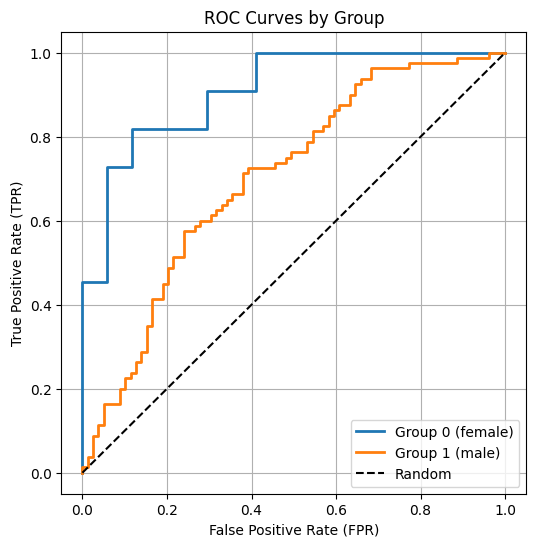

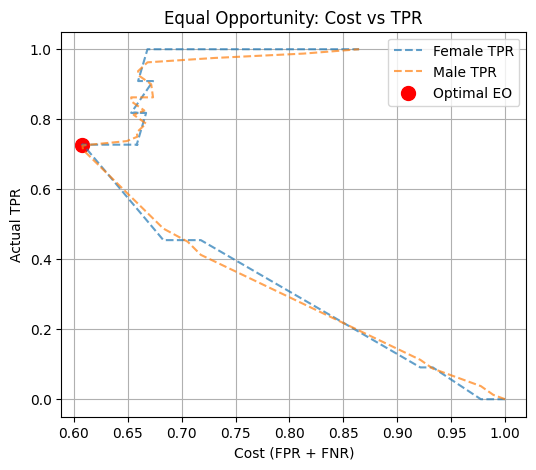

[EO] t0=0.521, t1=0.396, gap=0.002, acc=0.695, cost=0.608,  actual_tpr=0.726
Fold 1 | Acc=0.673 | Sens=0.700 | Spec=0.648 | TPR_gap=0.606 | FPR_gap=0.432 | DP_gap=0.540
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


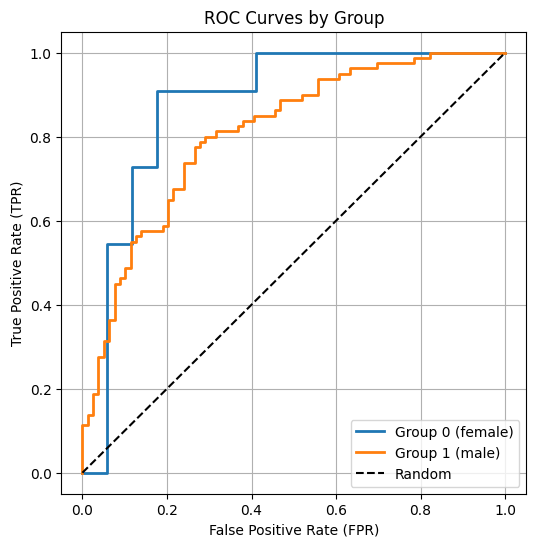

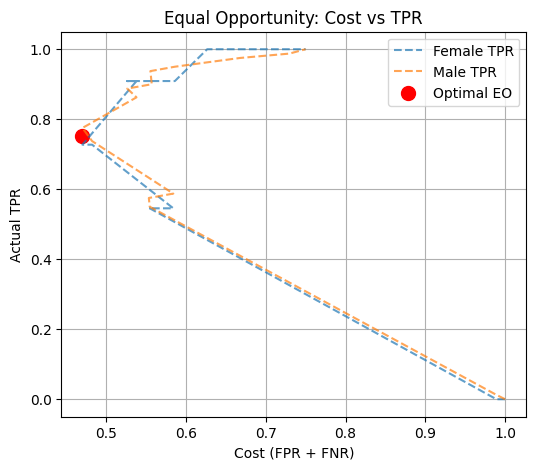

[EO] t0=0.580, t1=0.492, gap=0.048, acc=0.765, cost=0.470,  actual_tpr=0.751
Fold 2 | Acc=0.596 | Sens=0.580 | Spec=0.611 | TPR_gap=0.470 | FPR_gap=0.355 | DP_gap=0.420
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


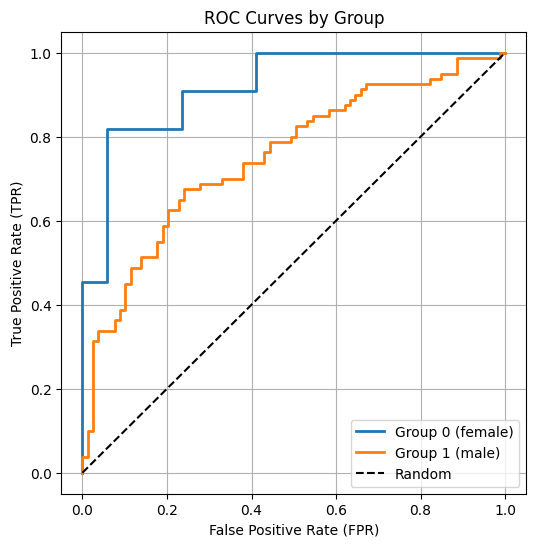

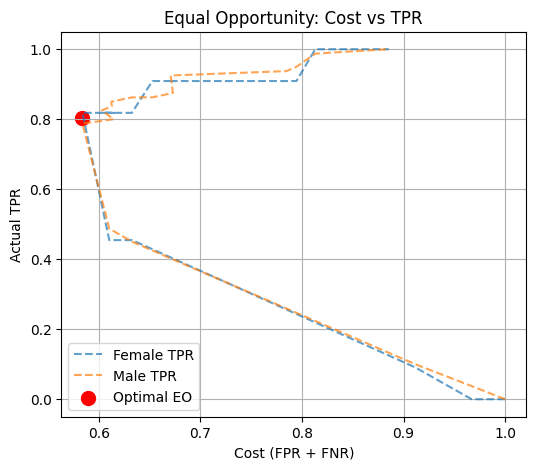

[EO] t0=0.544, t1=0.397, gap=0.031, acc=0.706, cost=0.584,  actual_tpr=0.803
Fold 3 | Acc=0.635 | Sens=0.740 | Spec=0.537 | TPR_gap=0.273 | FPR_gap=0.568 | DP_gap=0.483
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


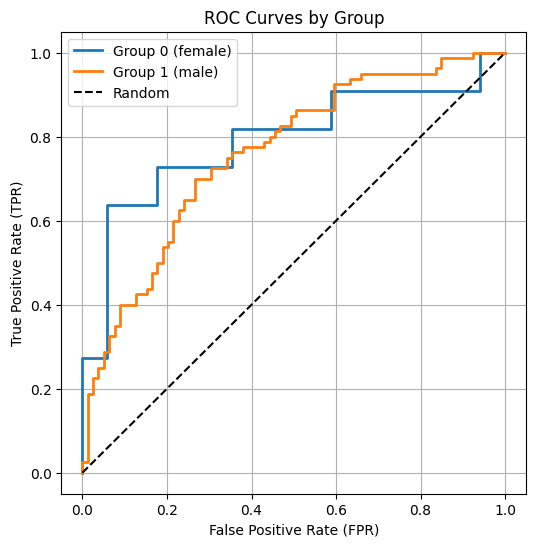

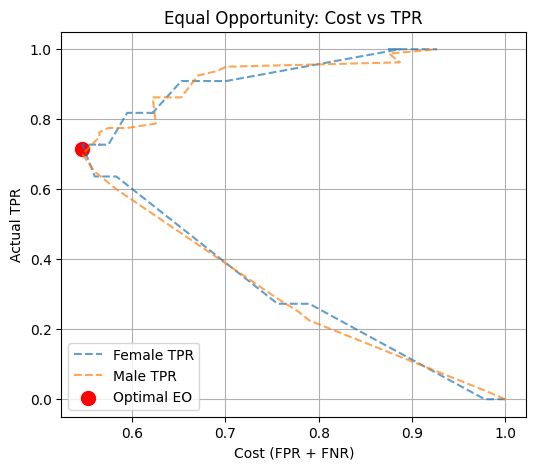

[EO] t0=0.413, t1=0.475, gap=0.027, acc=0.727, cost=0.547,  actual_tpr=0.714
Fold 4 | Acc=0.731 | Sens=0.680 | Spec=0.778 | TPR_gap=0.205 | FPR_gap=0.341 | DP_gap=0.068
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


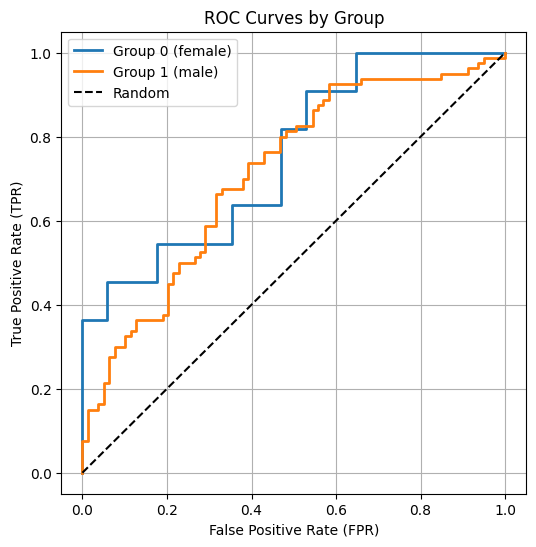

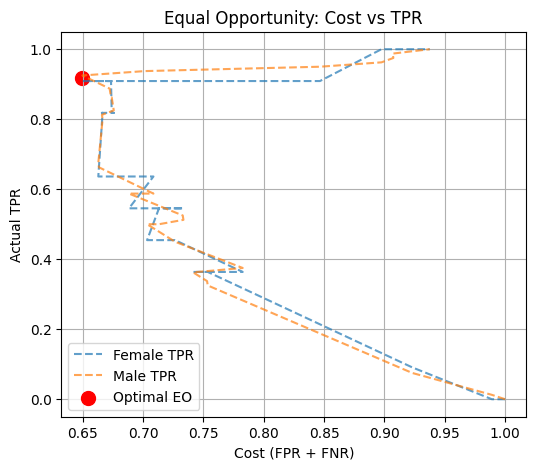

[EO] t0=0.381, t1=0.342, gap=0.016, acc=0.668, cost=0.650,  actual_tpr=0.917
Fold 5 | Acc=0.606 | Sens=0.880 | Spec=0.352 | TPR_gap=0.053 | FPR_gap=0.550 | DP_gap=0.381
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


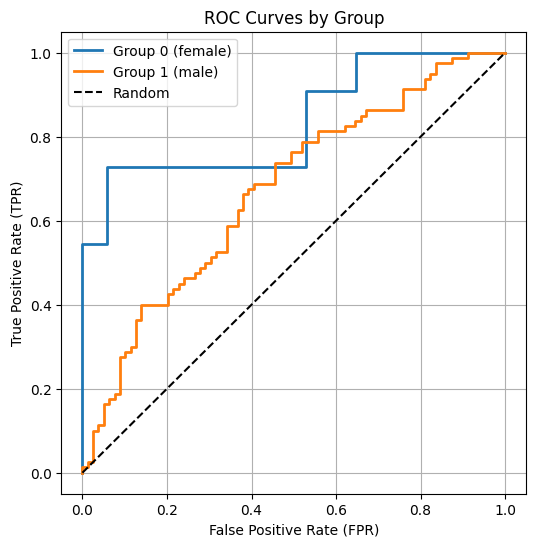

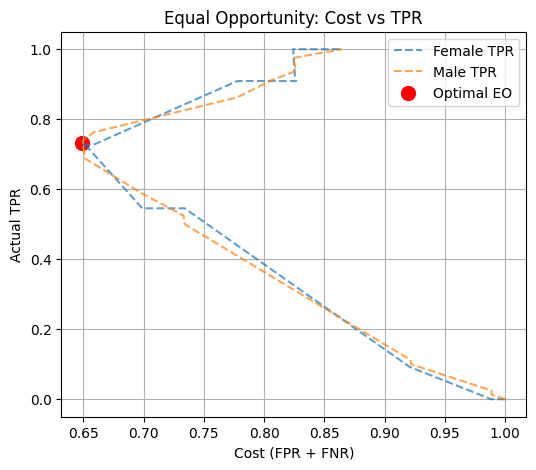

[EO] t0=0.653, t1=0.507, gap=0.010, acc=0.674, cost=0.649,  actual_tpr=0.732
Fold 6 | Acc=0.738 | Sens=0.765 | Spec=0.712 | TPR_gap=0.489 | FPR_gap=0.080 | DP_gap=0.302
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


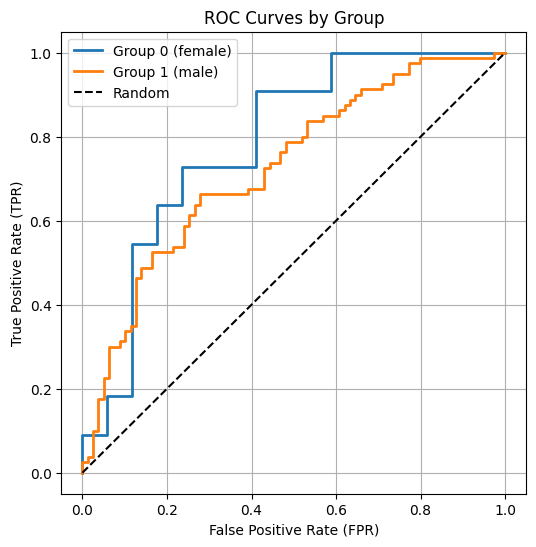

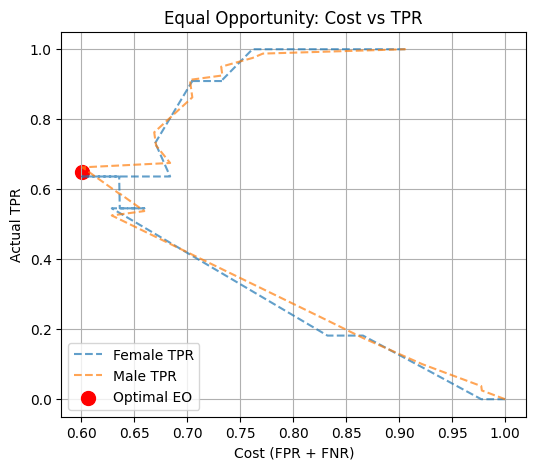

[EO] t0=0.540, t1=0.498, gap=0.026, acc=0.701, cost=0.601,  actual_tpr=0.649
Fold 7 | Acc=0.641 | Sens=0.627 | Spec=0.654 | TPR_gap=0.044 | FPR_gap=0.419 | DP_gap=0.256
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


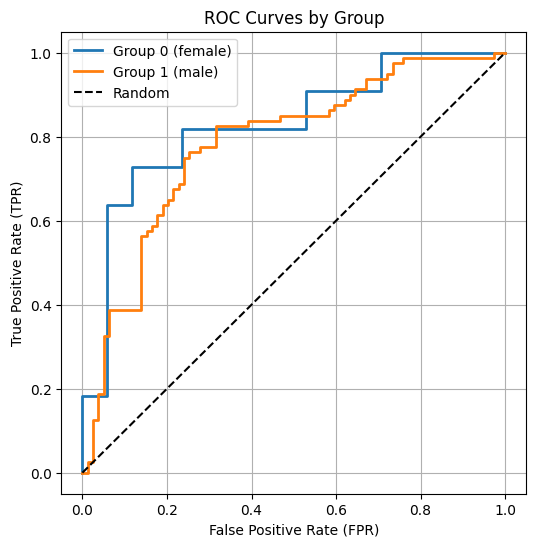

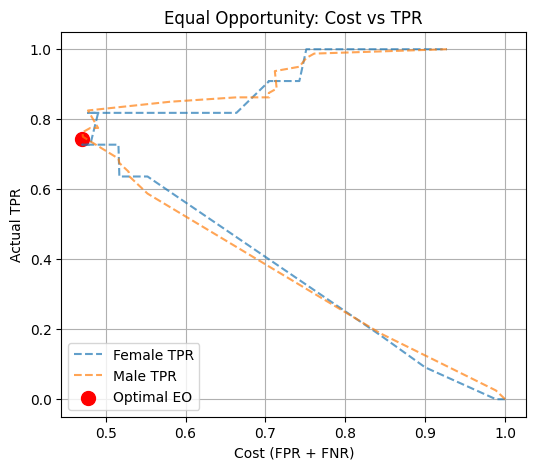

[EO] t0=0.534, t1=0.536, gap=0.035, acc=0.765, cost=0.471,  actual_tpr=0.745
Fold 8 | Acc=0.650 | Sens=0.490 | Spec=0.808 | TPR_gap=0.200 | FPR_gap=0.233 | DP_gap=0.086
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


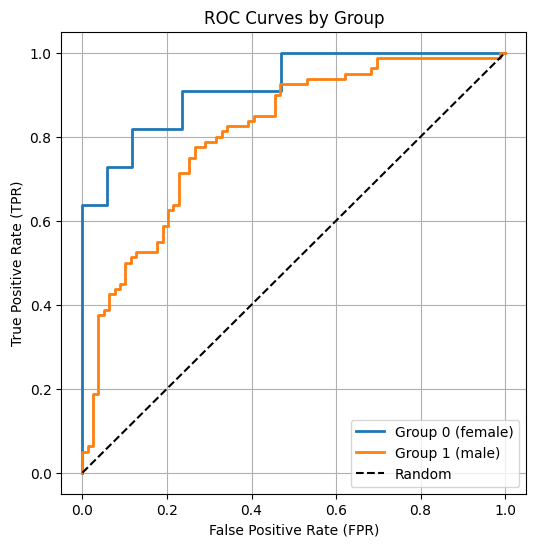

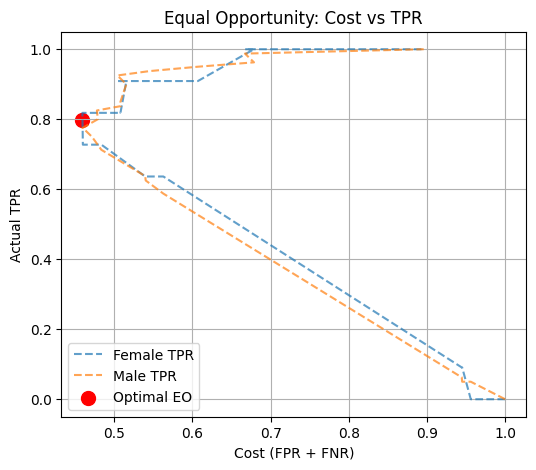

[EO] t0=0.558, t1=0.563, gap=0.043, acc=0.770, cost=0.459,  actual_tpr=0.797
Fold 9 | Acc=0.641 | Sens=0.490 | Spec=0.788 | TPR_gap=0.237 | FPR_gap=0.121 | DP_gap=0.192
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


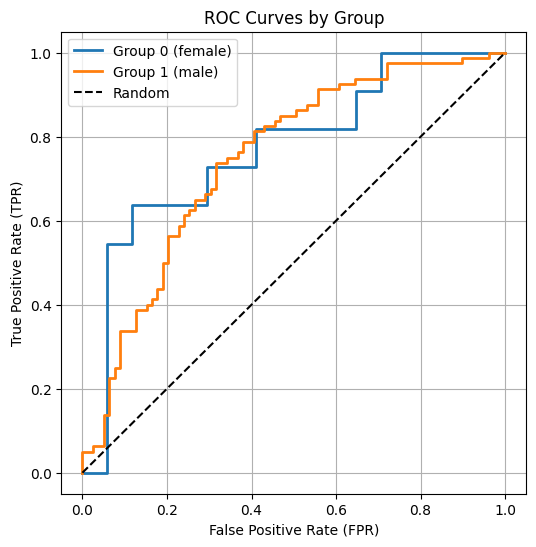

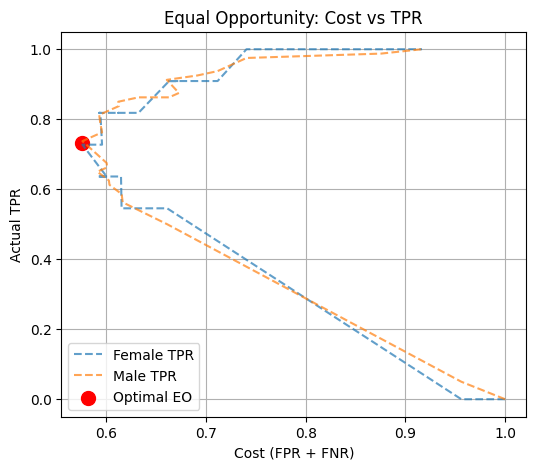

[EO] t0=0.408, t1=0.424, gap=0.010, acc=0.711, cost=0.576,  actual_tpr=0.732
Fold 10 | Acc=0.718 | Sens=0.686 | Spec=0.750 | TPR_gap=0.032 | FPR_gap=0.168 | DP_gap=0.108
performance (mean across folds):)
Accuracy: 0.6628734129947722
Std Accuracy: 0.04802793842176057
Sensitivity: 0.6638823529411765
Std Sensitivity: 0.11551152637669829
Specifity: 0.6637464387464387
Std Specifity: 0.13245621000087432

Fairness:
Mean TPR Gap: 0.26088744588744583
Std TPR Gap: 0.19093199827336432
Mean FPR Gap: 0.3266126380079869
Std FPR Gap: 0.16298774080843098
Mean DP Gap: 0.2834796238244514
Std DP Gap: 0.16110620644839674
275.17569303512573
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


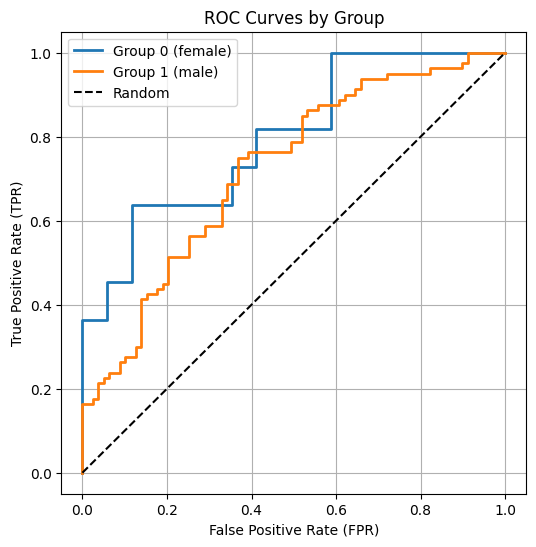

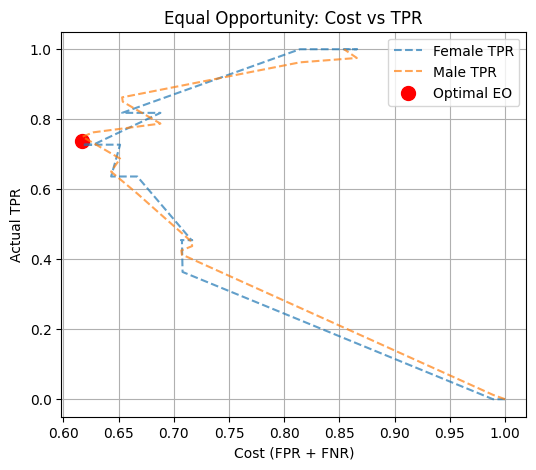

[EO] t0=0.464, t1=0.504, gap=0.023, acc=0.690, cost=0.617,  actual_tpr=0.739
Fold 1 | Acc=0.635 | Sens=0.640 | Spec=0.630 | TPR_gap=0.159 | FPR_gap=0.086 | DP_gap=0.148
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


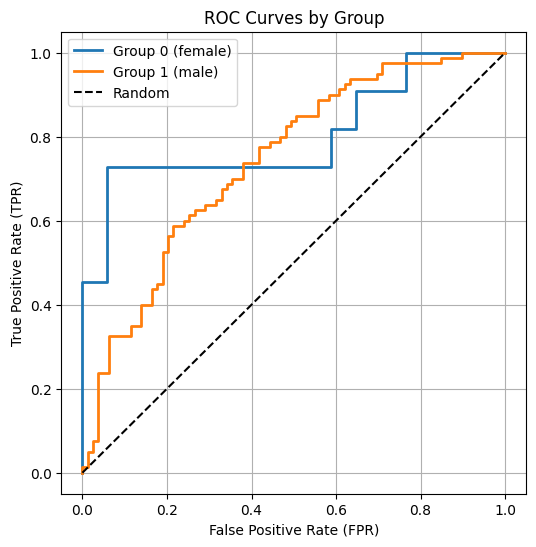

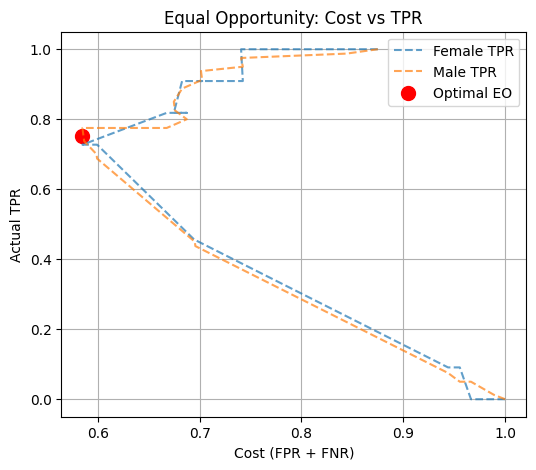

[EO] t0=0.518, t1=0.472, gap=0.048, acc=0.706, cost=0.585,  actual_tpr=0.751
Fold 2 | Acc=0.712 | Sens=0.700 | Spec=0.722 | TPR_gap=0.417 | FPR_gap=0.218 | DP_gap=0.347
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


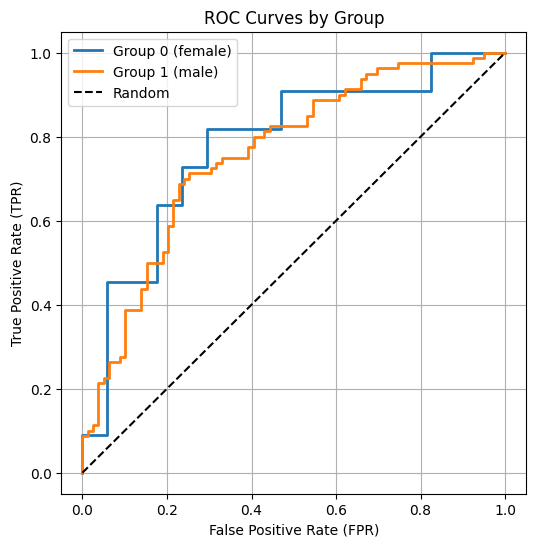

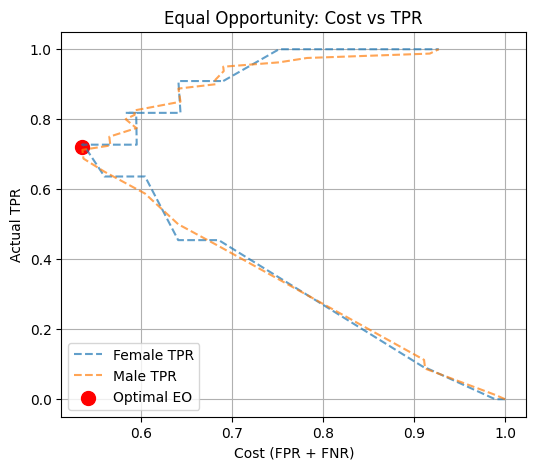

[EO] t0=0.532, t1=0.552, gap=0.015, acc=0.733, cost=0.536,  actual_tpr=0.720
Fold 3 | Acc=0.692 | Sens=0.720 | Spec=0.667 | TPR_gap=0.061 | FPR_gap=0.409 | DP_gap=0.318
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


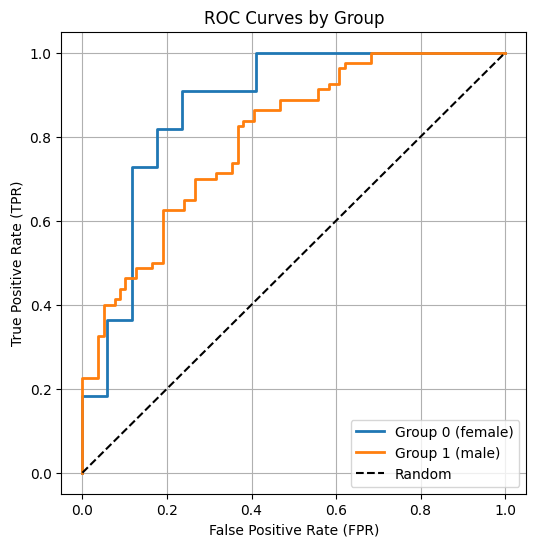

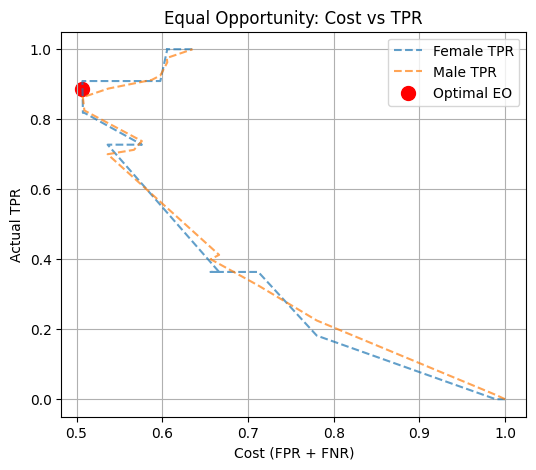

[EO] t0=0.412, t1=0.406, gap=0.047, acc=0.743, cost=0.507,  actual_tpr=0.886
Fold 4 | Acc=0.712 | Sens=0.800 | Spec=0.630 | TPR_gap=0.038 | FPR_gap=0.332 | DP_gap=0.239
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


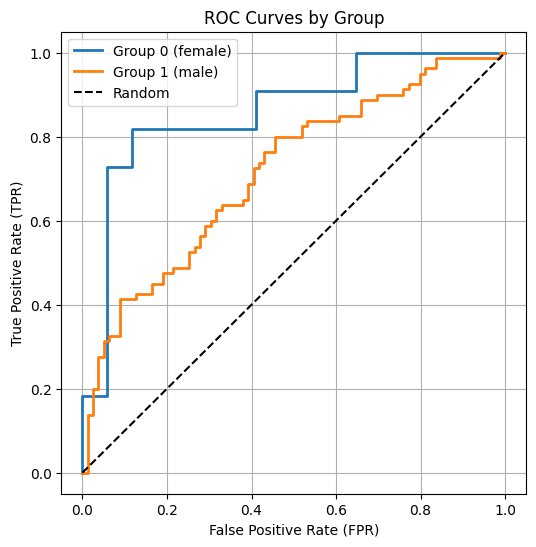

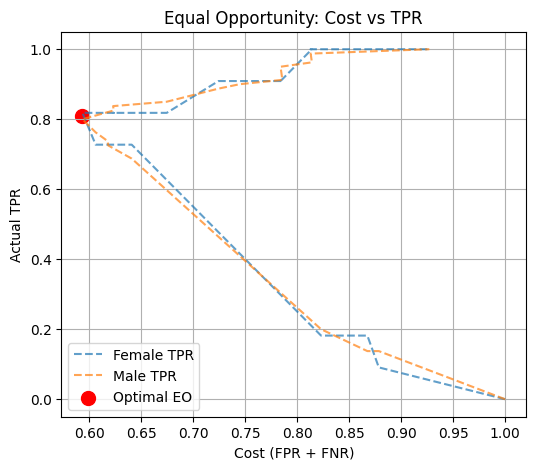

[EO] t0=0.491, t1=0.434, gap=0.018, acc=0.701, cost=0.594,  actual_tpr=0.809
Fold 5 | Acc=0.625 | Sens=0.760 | Spec=0.500 | TPR_gap=0.295 | FPR_gap=0.123 | DP_gap=0.222
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


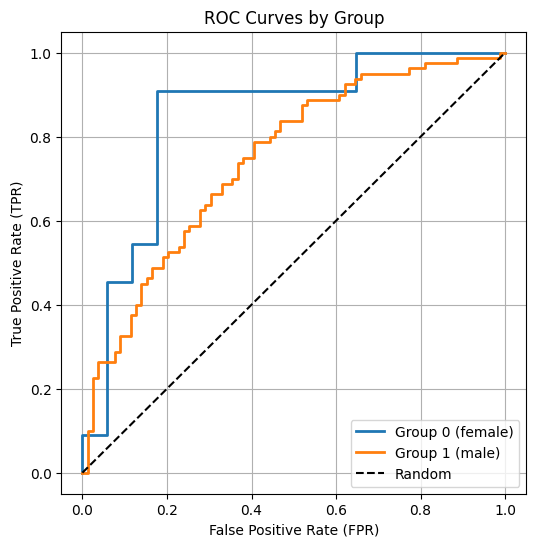

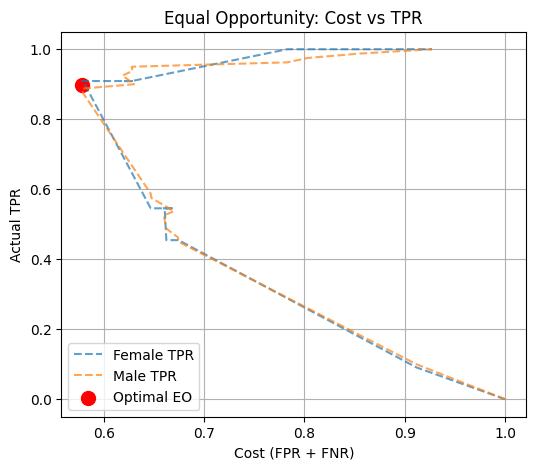

[EO] t0=0.453, t1=0.356, gap=0.022, acc=0.706, cost=0.579,  actual_tpr=0.898
Fold 6 | Acc=0.680 | Sens=0.863 | Spec=0.500 | TPR_gap=0.411 | FPR_gap=0.470 | DP_gap=0.483
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


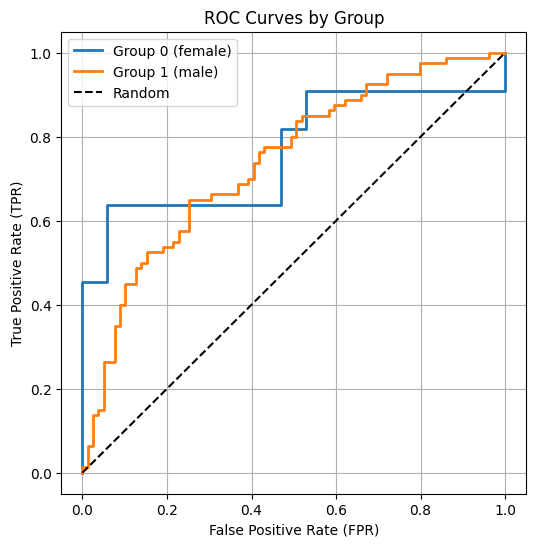

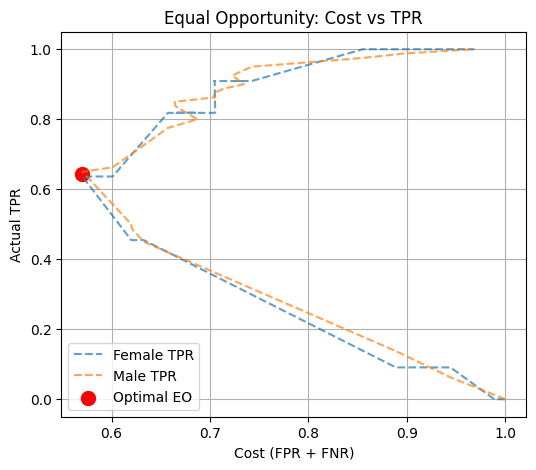

[EO] t0=0.495, t1=0.468, gap=0.014, acc=0.717, cost=0.570,  actual_tpr=0.643
Fold 7 | Acc=0.670 | Sens=0.549 | Spec=0.788 | TPR_gap=0.244 | FPR_gap=0.147 | DP_gap=0.053
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


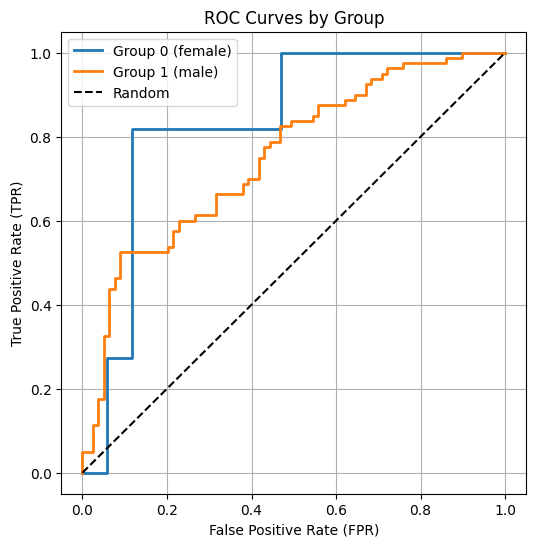

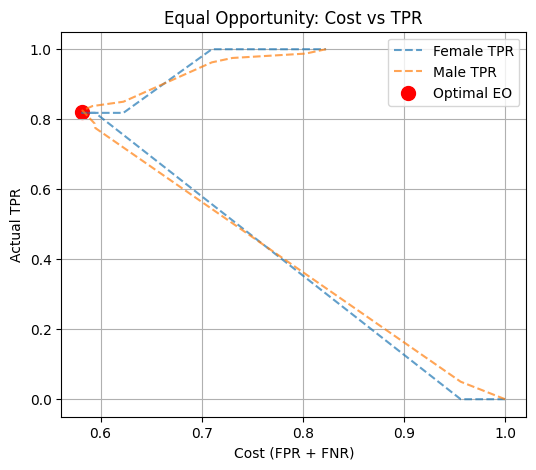

[EO] t0=0.440, t1=0.357, gap=0.007, acc=0.706, cost=0.582,  actual_tpr=0.822
Fold 8 | Acc=0.757 | Sens=0.922 | Spec=0.596 | TPR_gap=0.289 | FPR_gap=0.354 | DP_gap=0.383
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


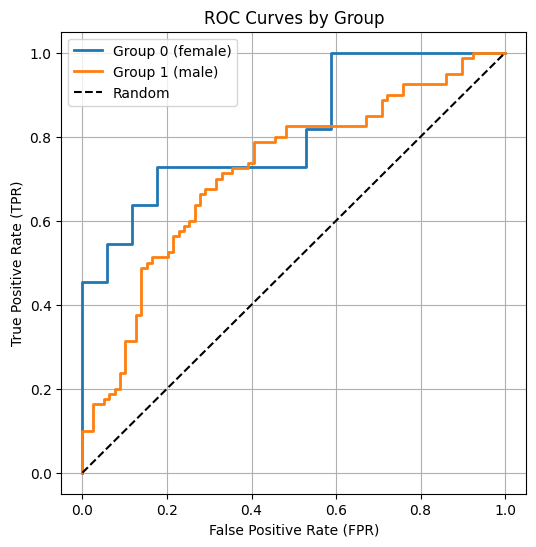

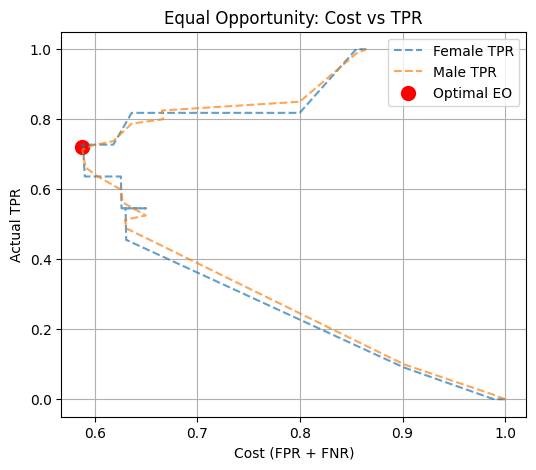

[EO] t0=0.527, t1=0.485, gap=0.015, acc=0.706, cost=0.588,  actual_tpr=0.720
Fold 9 | Acc=0.748 | Sens=0.686 | Spec=0.808 | TPR_gap=0.133 | FPR_gap=0.036 | DP_gap=0.073
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


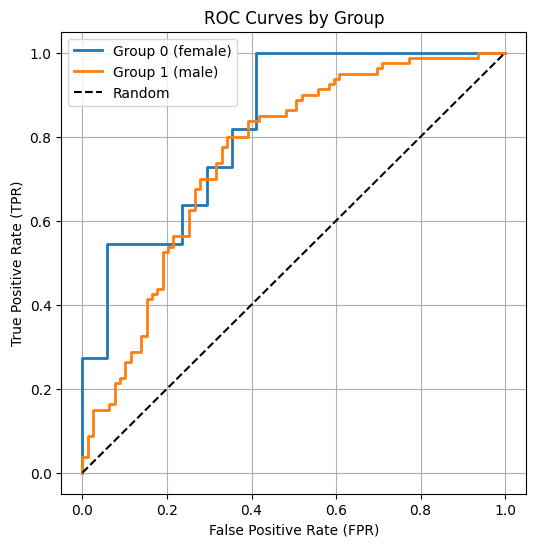

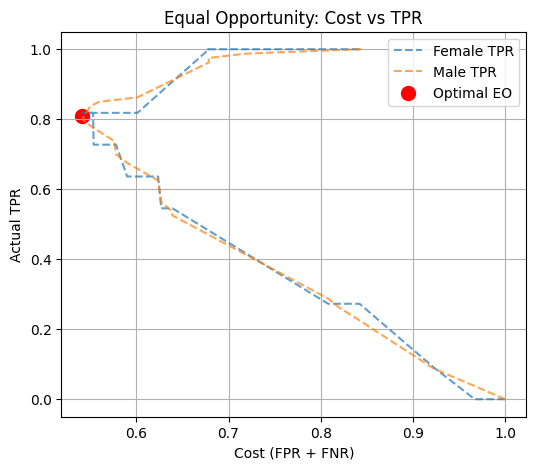

[EO] t0=0.374, t1=0.499, gap=0.018, acc=0.727, cost=0.542,  actual_tpr=0.809
Fold 10 | Acc=0.631 | Sens=0.667 | Spec=0.596 | TPR_gap=0.221 | FPR_gap=0.183 | DP_gap=0.182
performance (mean across folds):)
Accuracy: 0.6860436893203884
Std Accuracy: 0.04460414803377757
Sensitivity: 0.7306274509803922
Std Sensitivity: 0.1038714566562036
Specifity: 0.6436609686609686
Std Specifity: 0.10037887031735444

Fairness:
Mean TPR Gap: 0.22680375180375184
Std TPR Gap: 0.12474321097673584
Mean FPR Gap: 0.23593962884660558
Std FPR Gap: 0.13930365173366288
Mean DP Gap: 0.24466954022988513
Std DP Gap: 0.13107145918062268
549.4082293510437
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


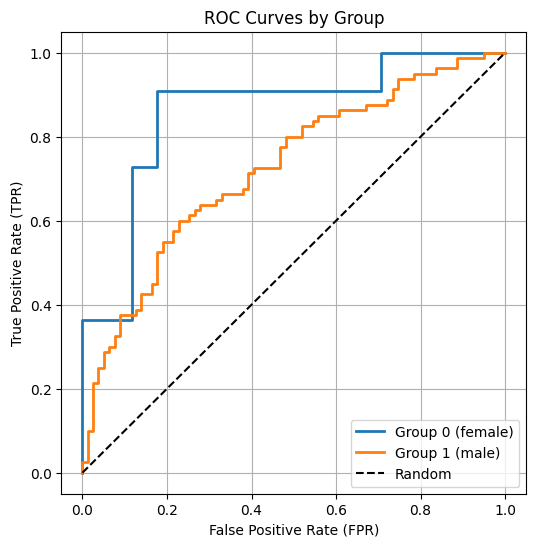

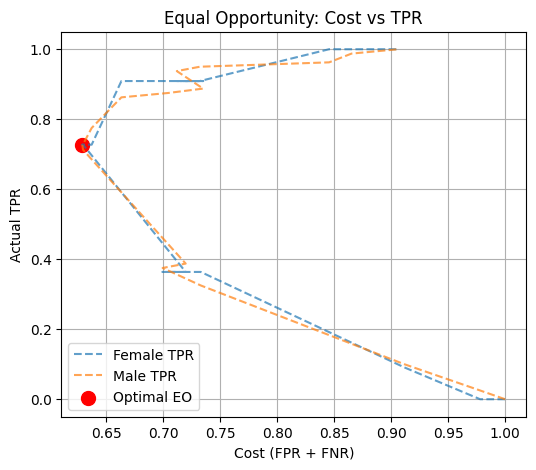

[EO] t0=0.473, t1=0.483, gap=0.002, acc=0.684, cost=0.629,  actual_tpr=0.726
Fold 1 | Acc=0.712 | Sens=0.720 | Spec=0.704 | TPR_gap=0.439 | FPR_gap=0.118 | DP_gap=0.295
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


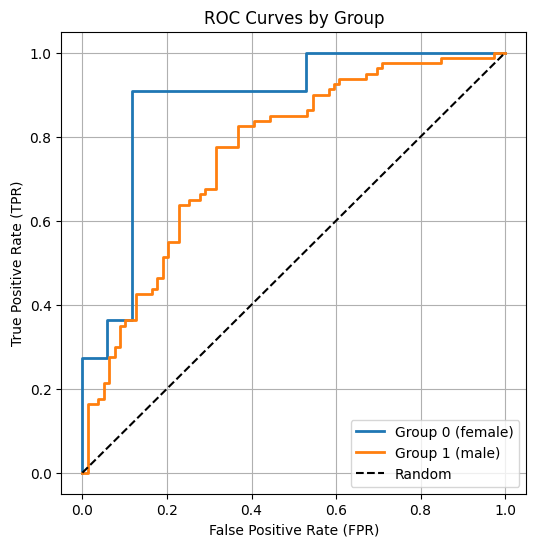

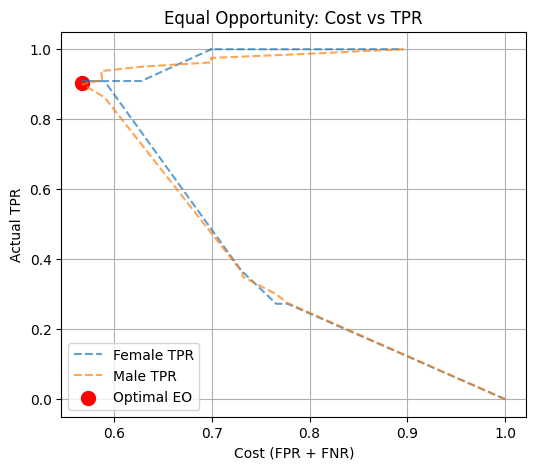

[EO] t0=0.453, t1=0.298, gap=0.009, acc=0.711, cost=0.568,  actual_tpr=0.905
Fold 2 | Acc=0.635 | Sens=0.800 | Spec=0.481 | TPR_gap=0.341 | FPR_gap=0.391 | DP_gap=0.403
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


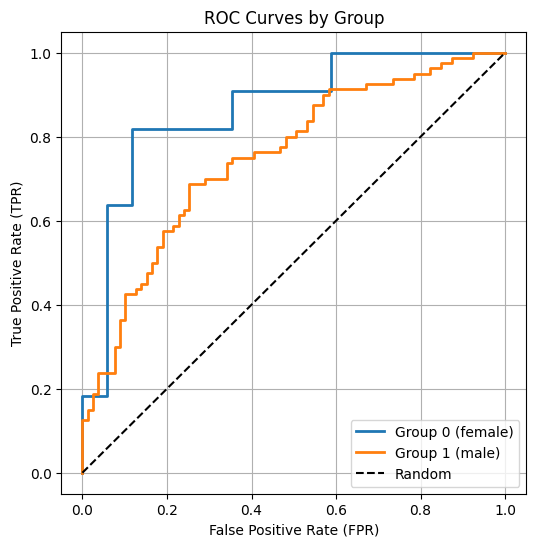

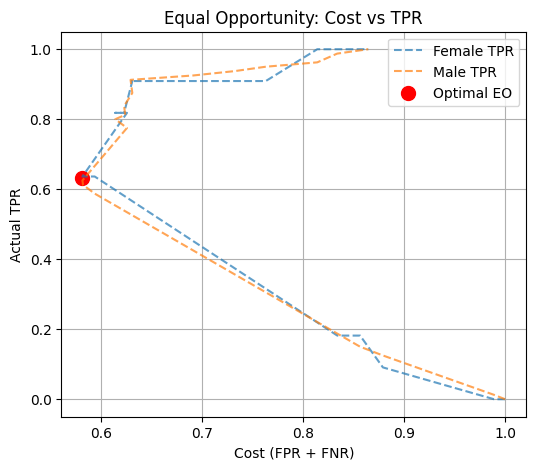

[EO] t0=0.574, t1=0.544, gap=0.011, acc=0.711, cost=0.582,  actual_tpr=0.631
Fold 3 | Acc=0.654 | Sens=0.540 | Spec=0.759 | TPR_gap=0.045 | FPR_gap=0.295 | DP_gap=0.233
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


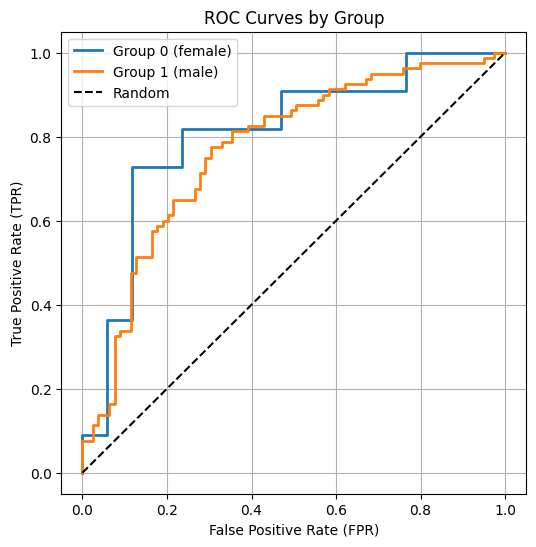

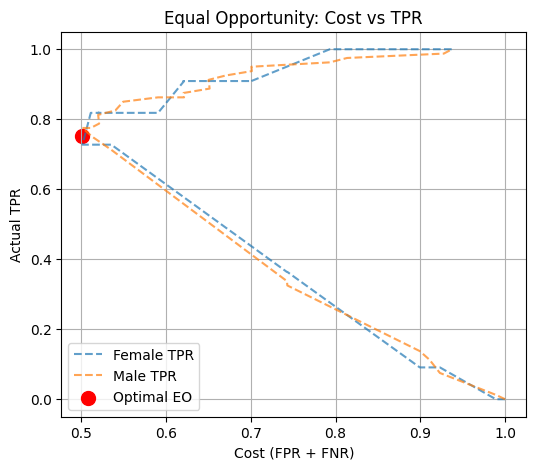

[EO] t0=0.602, t1=0.512, gap=0.048, acc=0.749, cost=0.502,  actual_tpr=0.751
Fold 4 | Acc=0.692 | Sens=0.640 | Spec=0.741 | TPR_gap=0.348 | FPR_gap=0.195 | DP_gap=0.301
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


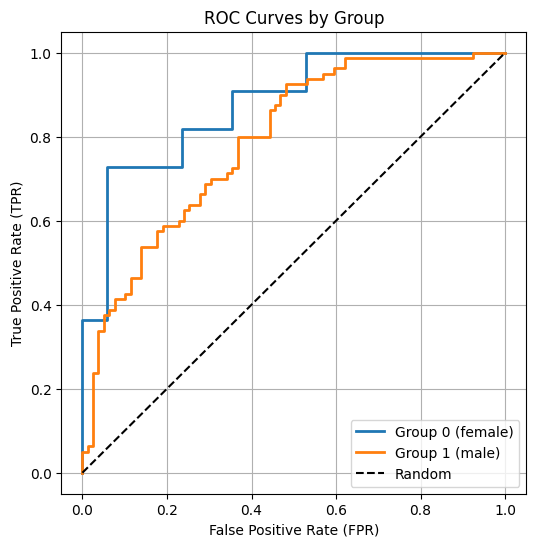

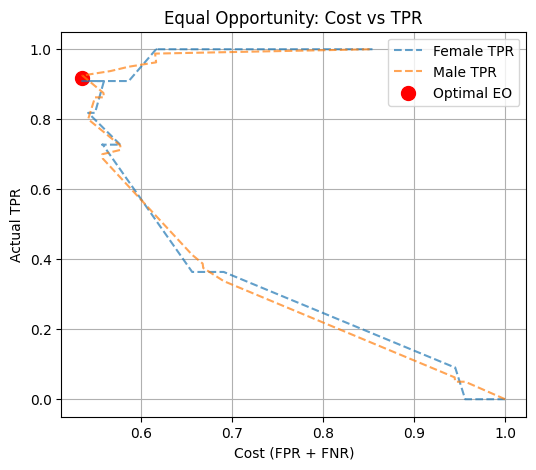

[EO] t0=0.465, t1=0.397, gap=0.016, acc=0.727, cost=0.535,  actual_tpr=0.917
Fold 5 | Acc=0.596 | Sens=0.800 | Spec=0.407 | TPR_gap=0.152 | FPR_gap=0.605 | DP_gap=0.449
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


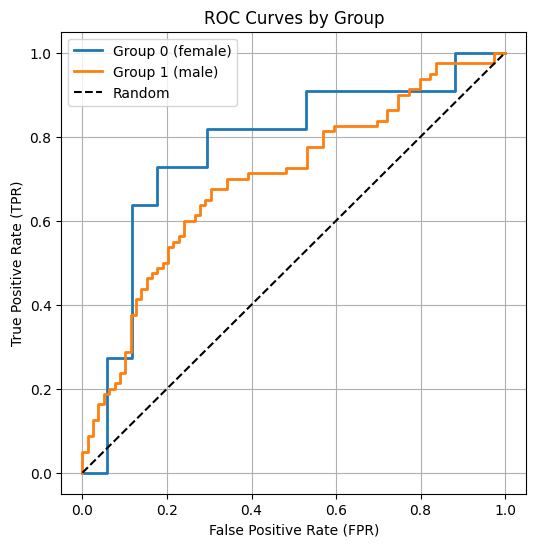

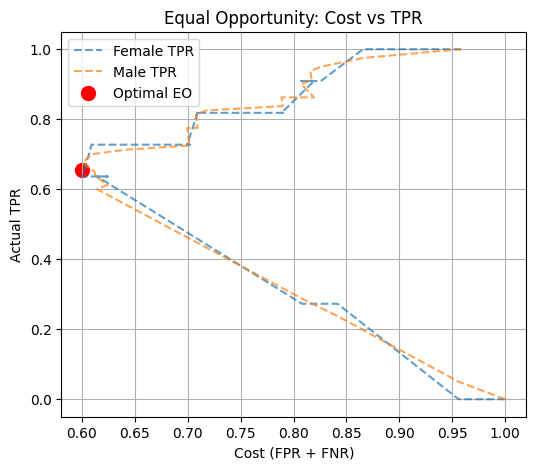

[EO] t0=0.567, t1=0.474, gap=0.039, acc=0.701, cost=0.601,  actual_tpr=0.656
Fold 6 | Acc=0.709 | Sens=0.608 | Spec=0.808 | TPR_gap=0.311 | FPR_gap=0.233 | DP_gap=0.310
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


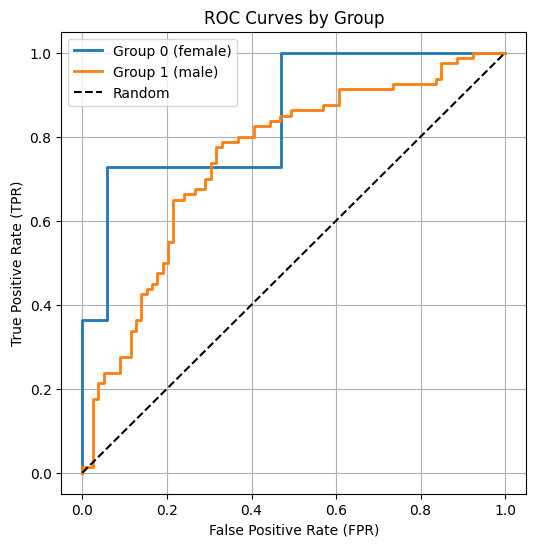

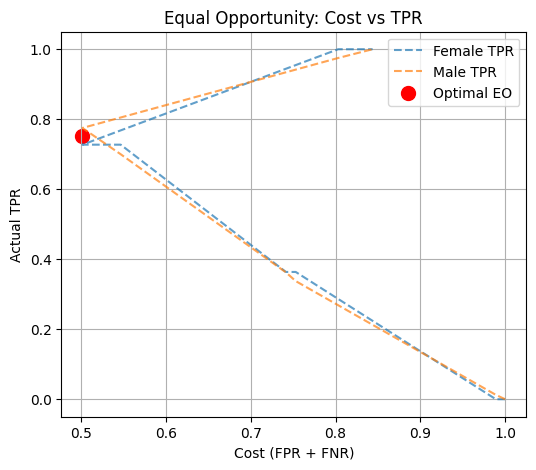

[EO] t0=0.476, t1=0.491, gap=0.048, acc=0.749, cost=0.502,  actual_tpr=0.751
Fold 7 | Acc=0.670 | Sens=0.824 | Spec=0.519 | TPR_gap=0.178 | FPR_gap=0.044 | DP_gap=0.137
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


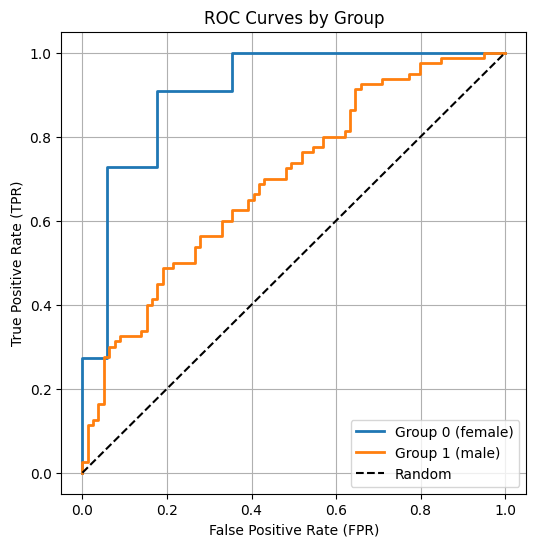

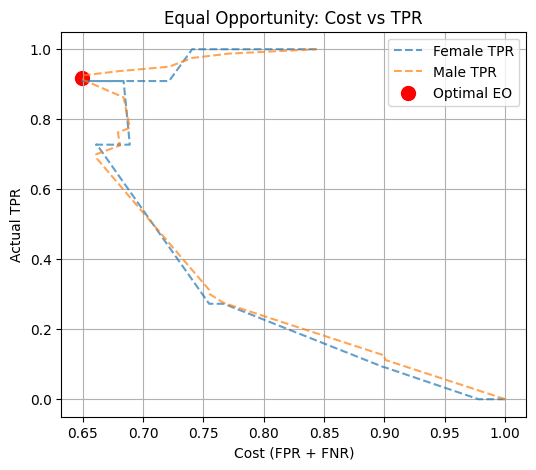

[EO] t0=0.469, t1=0.347, gap=0.016, acc=0.668, cost=0.650,  actual_tpr=0.917
Fold 8 | Acc=0.689 | Sens=0.961 | Spec=0.423 | TPR_gap=0.144 | FPR_gap=0.429 | DP_gap=0.352
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


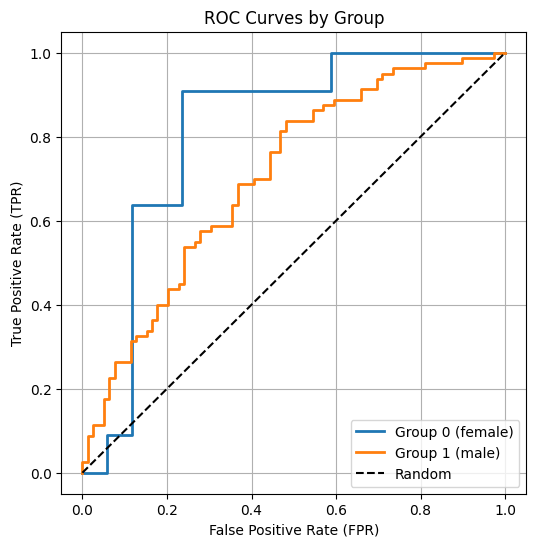

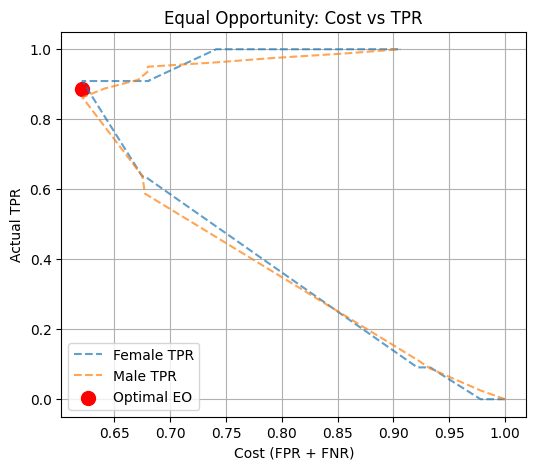

[EO] t0=0.491, t1=0.418, gap=0.047, acc=0.684, cost=0.621,  actual_tpr=0.886
Fold 9 | Acc=0.612 | Sens=0.745 | Spec=0.481 | TPR_gap=0.201 | FPR_gap=0.090 | DP_gap=0.155
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


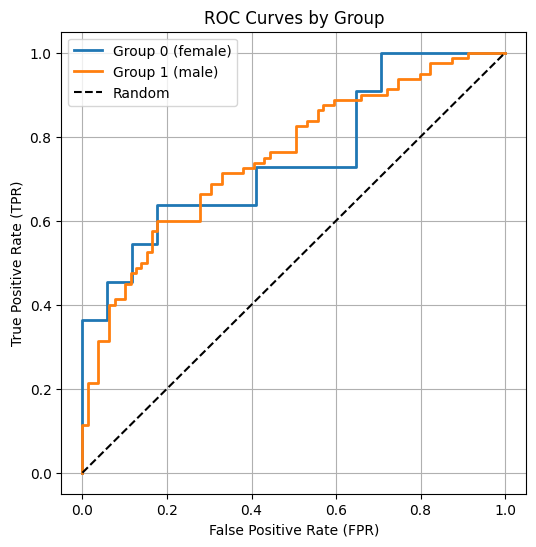

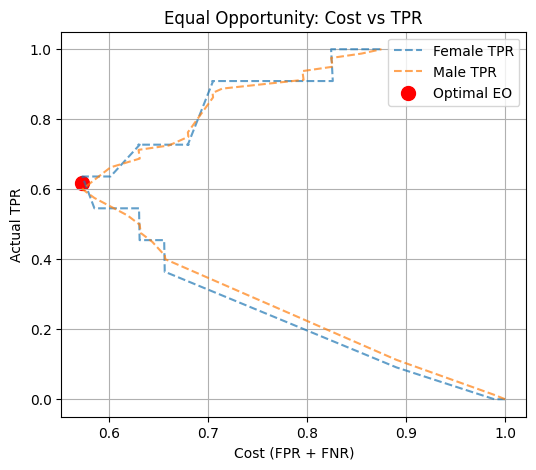

[EO] t0=0.426, t1=0.523, gap=0.036, acc=0.717, cost=0.573,  actual_tpr=0.618
Fold 10 | Acc=0.680 | Sens=0.529 | Spec=0.827 | TPR_gap=0.214 | FPR_gap=0.194 | DP_gap=0.178
performance (mean across folds):)
Accuracy: 0.6647684839432413
Std Accuracy: 0.03779764560120695
Sensitivity: 0.7166666666666667
Std Sensitivity: 0.1302755781377734
Specifity: 0.61502849002849
Std Specifity: 0.15858042577413473

Fairness:
Mean TPR Gap: 0.23746753246753247
Std TPR Gap: 0.11293413686471869
Mean FPR Gap: 0.25942095372327934
Std FPR Gap: 0.16446752300634235
Mean DP Gap: 0.28136363636363637
Std DP Gap: 0.09949764899575703
819.7207064628601
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


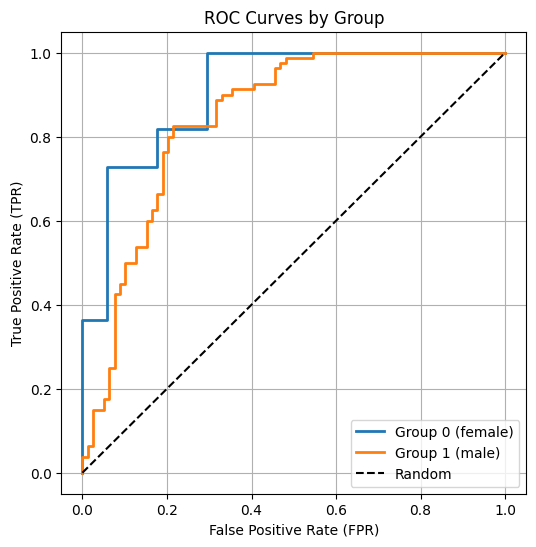

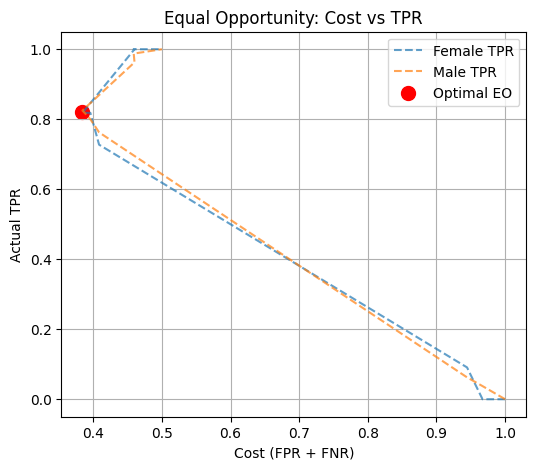

[EO] t0=0.488, t1=0.523, gap=0.007, acc=0.807, cost=0.384,  actual_tpr=0.822
Fold 1 | Acc=0.750 | Sens=0.760 | Spec=0.741 | TPR_gap=0.083 | FPR_gap=0.073 | DP_gap=0.074
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


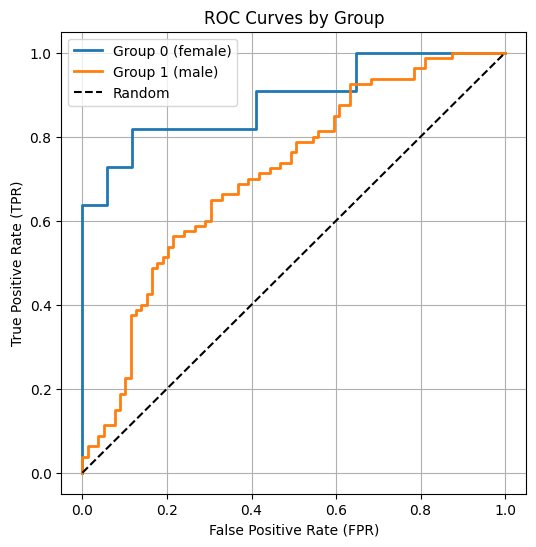

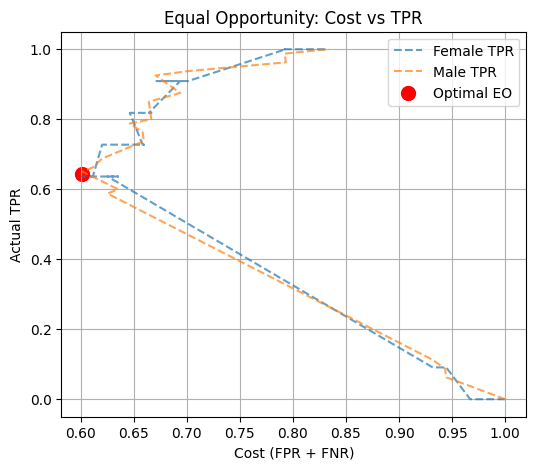

[EO] t0=0.583, t1=0.490, gap=0.014, acc=0.701, cost=0.602,  actual_tpr=0.643
Fold 2 | Acc=0.760 | Sens=0.700 | Spec=0.815 | TPR_gap=0.227 | FPR_gap=0.105 | DP_gap=0.216
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


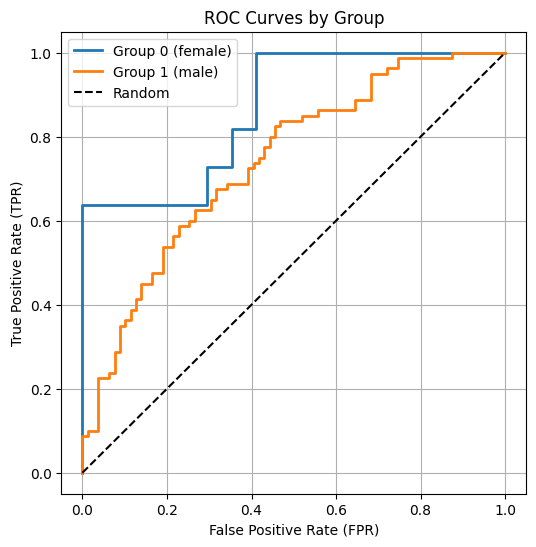

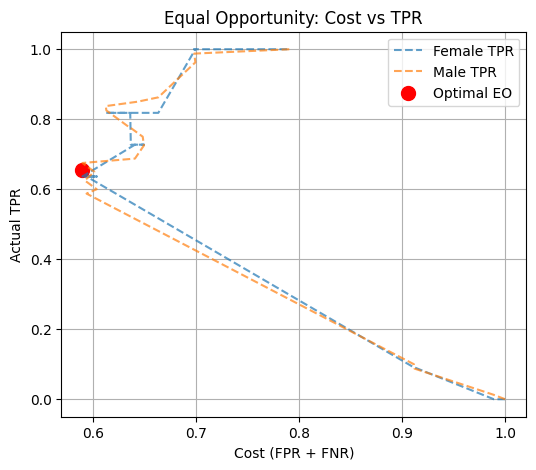

[EO] t0=0.685, t1=0.517, gap=0.039, acc=0.706, cost=0.590,  actual_tpr=0.656
Fold 3 | Acc=0.683 | Sens=0.600 | Spec=0.759 | TPR_gap=0.114 | FPR_gap=0.295 | DP_gap=0.267
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


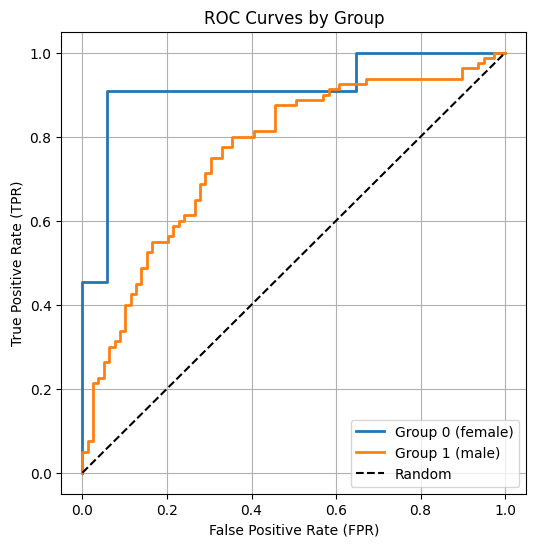

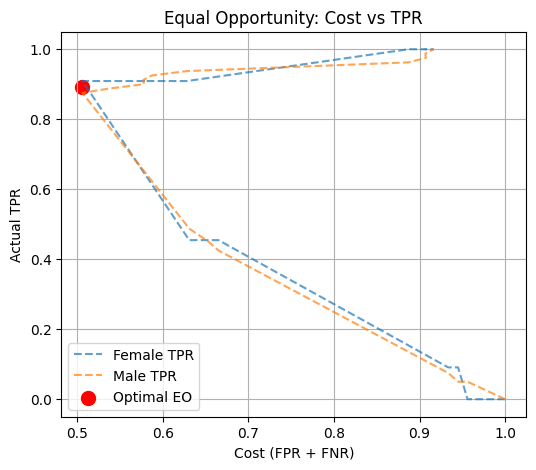

[EO] t0=0.555, t1=0.419, gap=0.034, acc=0.743, cost=0.506,  actual_tpr=0.892
Fold 4 | Acc=0.683 | Sens=0.760 | Spec=0.611 | TPR_gap=0.674 | FPR_gap=0.477 | DP_gap=0.597
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


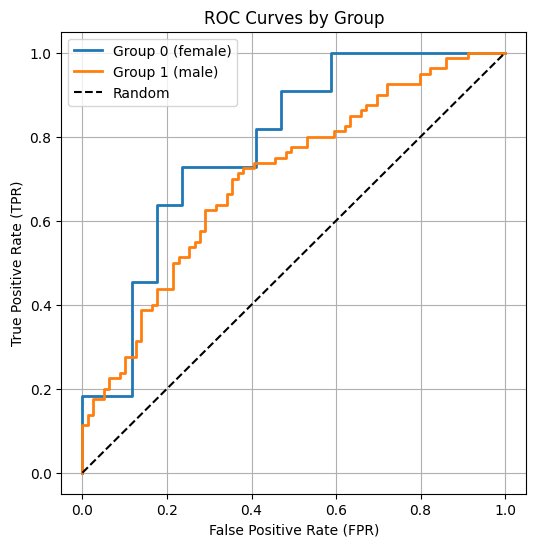

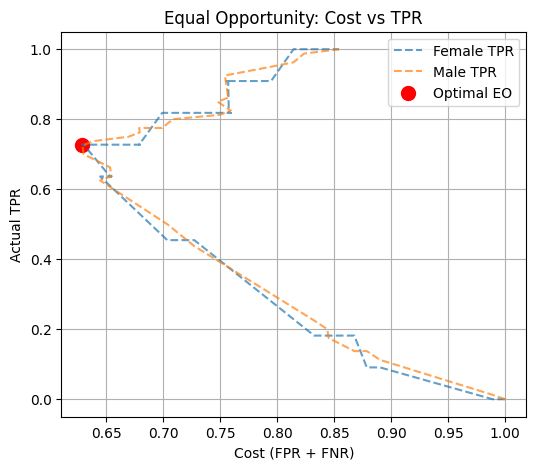

[EO] t0=0.505, t1=0.463, gap=0.002, acc=0.684, cost=0.629,  actual_tpr=0.726
Fold 5 | Acc=0.635 | Sens=0.540 | Spec=0.722 | TPR_gap=0.045 | FPR_gap=0.095 | DP_gap=0.108
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


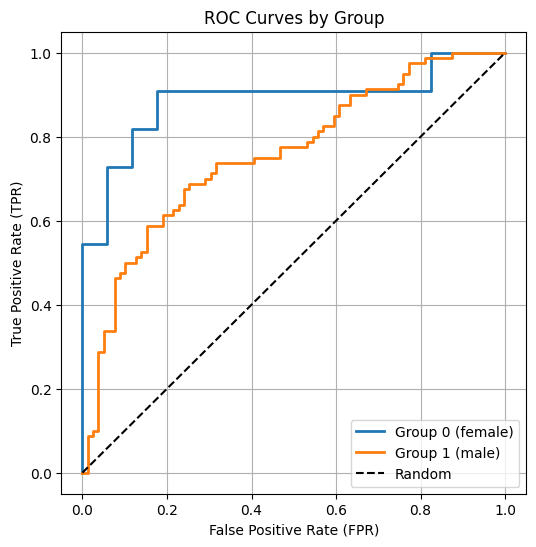

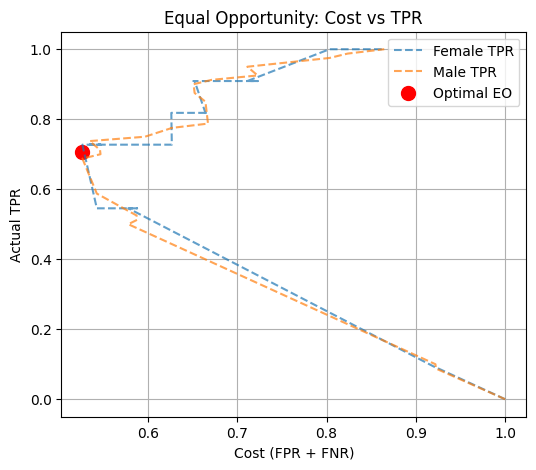

[EO] t0=0.543, t1=0.472, gap=0.040, acc=0.738, cost=0.526,  actual_tpr=0.707
Fold 6 | Acc=0.621 | Sens=0.588 | Spec=0.654 | TPR_gap=0.478 | FPR_gap=0.419 | DP_gap=0.467
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


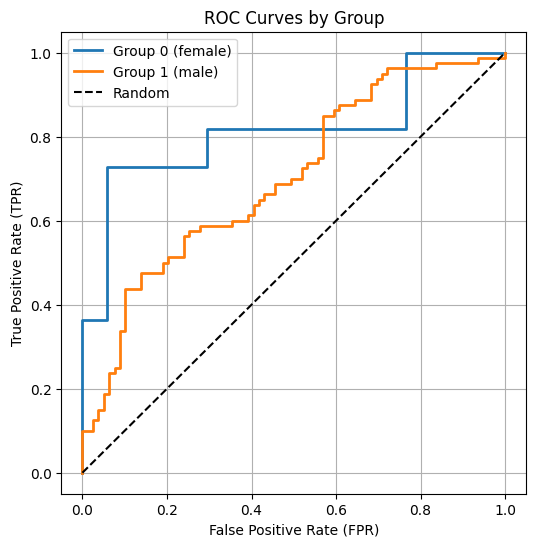

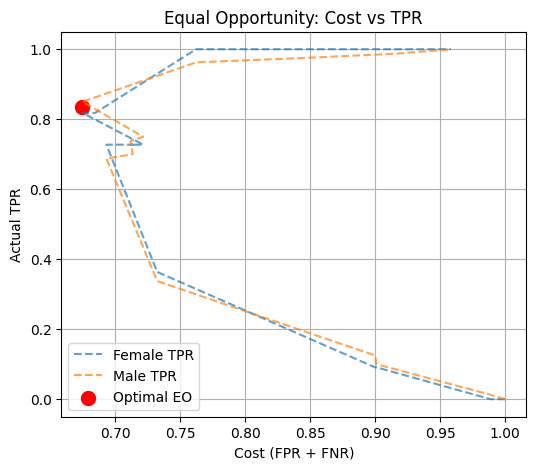

[EO] t0=0.409, t1=0.382, gap=0.032, acc=0.658, cost=0.675,  actual_tpr=0.834
Fold 7 | Acc=0.680 | Sens=0.784 | Spec=0.577 | TPR_gap=0.133 | FPR_gap=0.109 | DP_gap=0.158
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


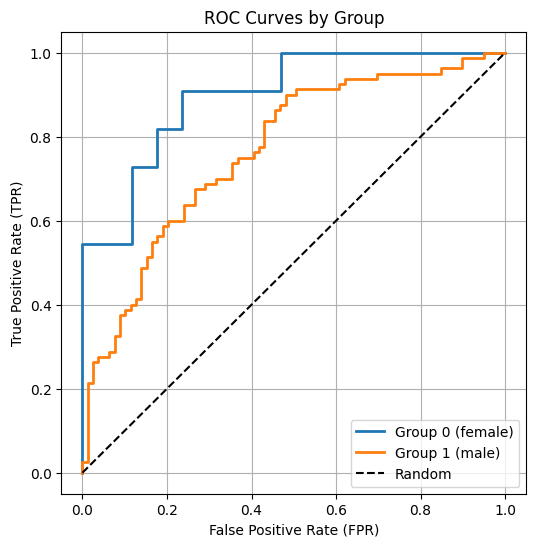

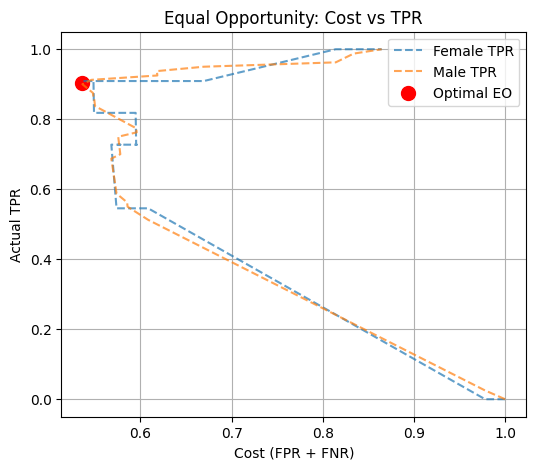

[EO] t0=0.404, t1=0.431, gap=0.009, acc=0.727, cost=0.536,  actual_tpr=0.905
Fold 8 | Acc=0.689 | Sens=0.843 | Spec=0.538 | TPR_gap=0.200 | FPR_gap=0.021 | DP_gap=0.137
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


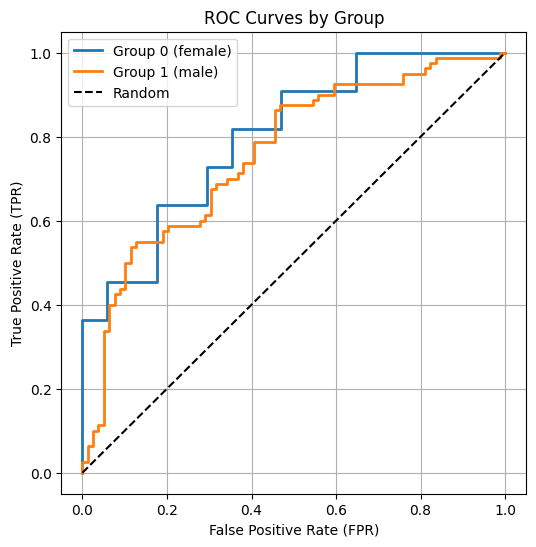

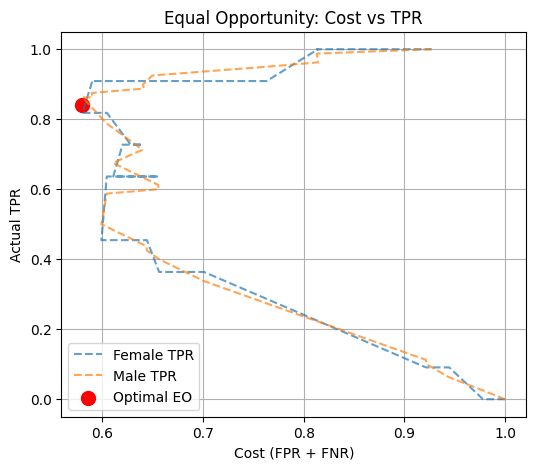

[EO] t0=0.415, t1=0.440, gap=0.044, acc=0.706, cost=0.580,  actual_tpr=0.840
Fold 9 | Acc=0.650 | Sens=0.824 | Spec=0.481 | TPR_gap=0.039 | FPR_gap=0.359 | DP_gap=0.201
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


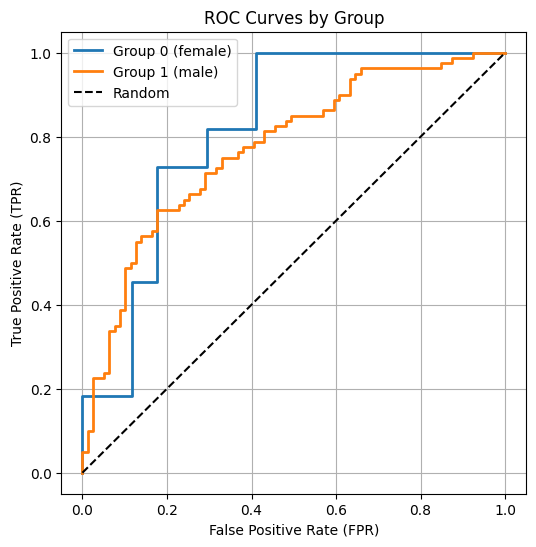

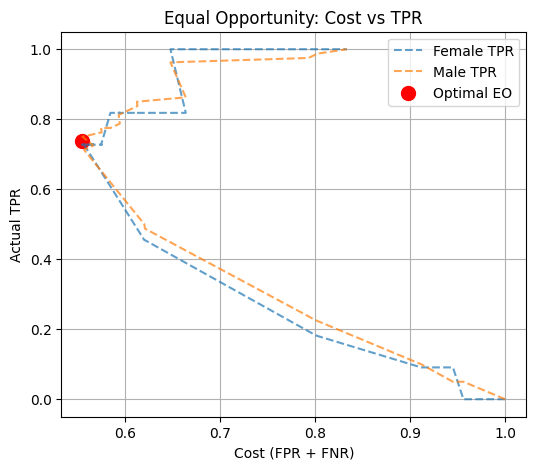

[EO] t0=0.425, t1=0.435, gap=0.023, acc=0.722, cost=0.555,  actual_tpr=0.739
Fold 10 | Acc=0.641 | Sens=0.627 | Spec=0.654 | TPR_gap=0.065 | FPR_gap=0.284 | DP_gap=0.205
performance (mean across folds):)
Accuracy: 0.6791168782673637
Std Accuracy: 0.043863890277963356
Sensitivity: 0.7026666666666668
Std Sensitivity: 0.10165637817360808
Specifity: 0.6551994301994302
Std Specifity: 0.10012150089079509

Fairness:
Mean TPR Gap: 0.20589466089466094
Std TPR Gap: 0.1990068633438366
Mean FPR Gap: 0.22366690157387836
Std FPR Gap: 0.1540701565582035
Mean DP Gap: 0.24301332288401256
Std DP Gap: 0.15657049855244368
1094.989471912384
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


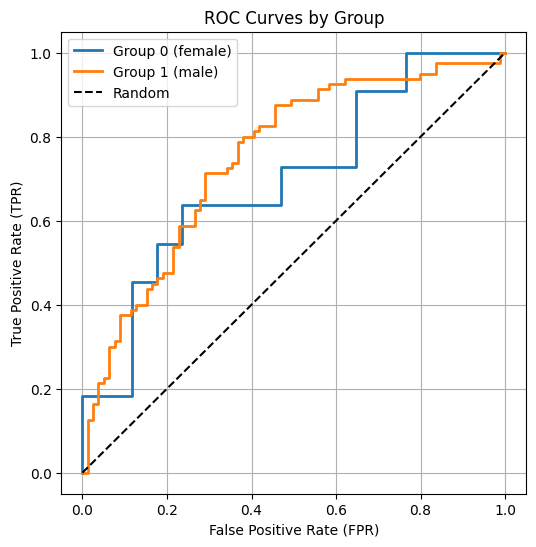

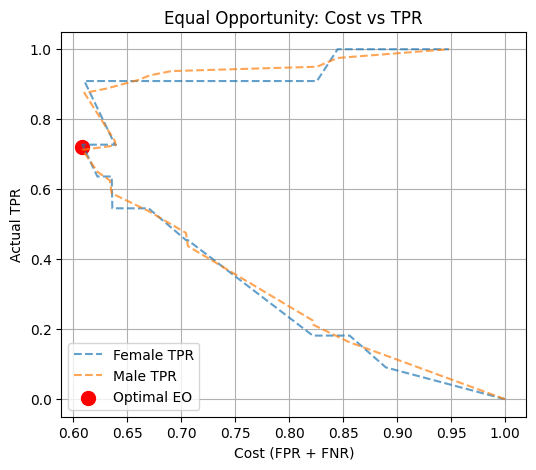

[EO] t0=0.415, t1=0.542, gap=0.015, acc=0.695, cost=0.609,  actual_tpr=0.720
Fold 1 | Acc=0.731 | Sens=0.700 | Spec=0.759 | TPR_gap=0.341 | FPR_gap=0.050 | DP_gap=0.045
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


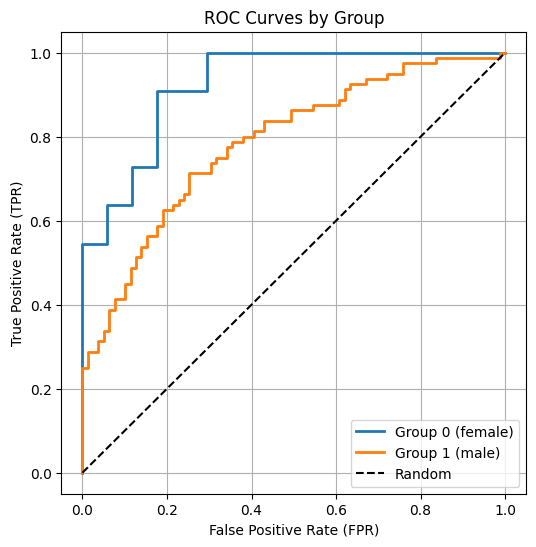

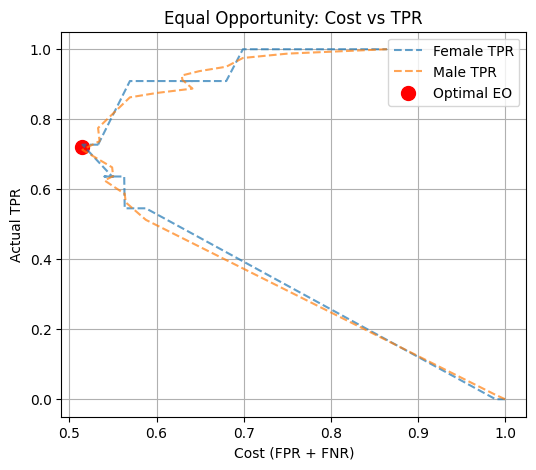

[EO] t0=0.482, t1=0.522, gap=0.015, acc=0.743, cost=0.515,  actual_tpr=0.720
Fold 2 | Acc=0.692 | Sens=0.700 | Spec=0.685 | TPR_gap=0.038 | FPR_gap=0.264 | DP_gap=0.222
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


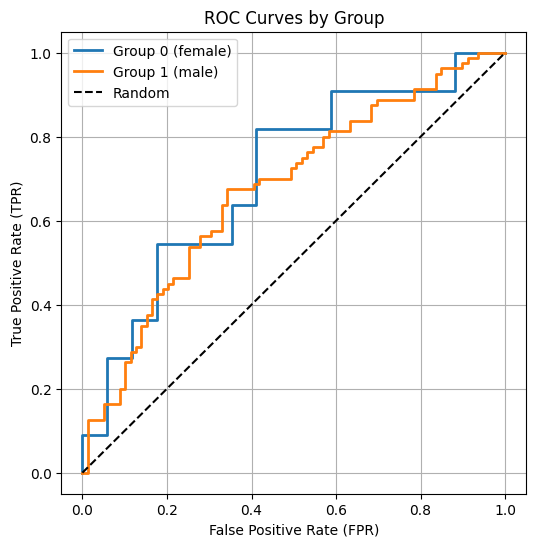

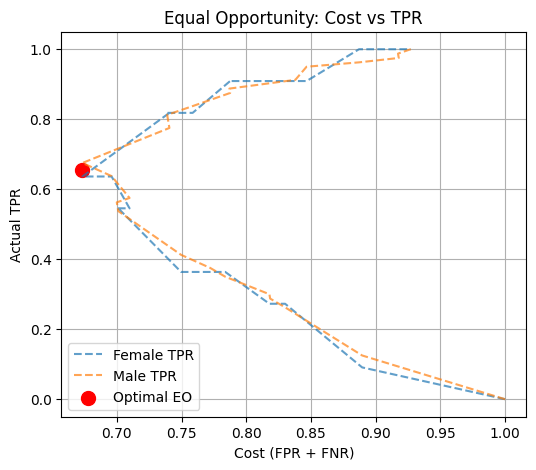

[EO] t0=0.401, t1=0.482, gap=0.039, acc=0.663, cost=0.673,  actual_tpr=0.656
Fold 3 | Acc=0.712 | Sens=0.720 | Spec=0.704 | TPR_gap=0.129 | FPR_gap=0.127 | DP_gap=0.074
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


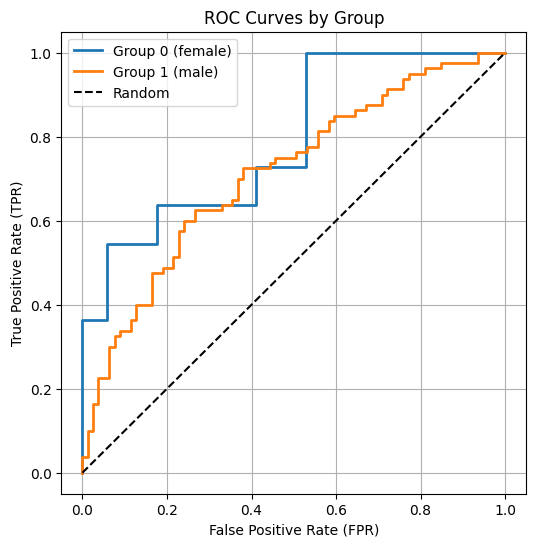

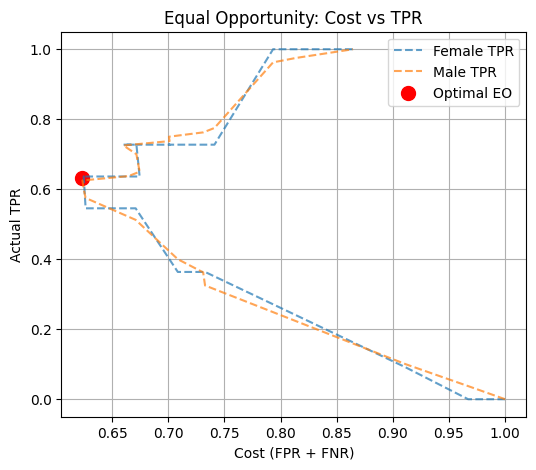

[EO] t0=0.454, t1=0.485, gap=0.011, acc=0.690, cost=0.624,  actual_tpr=0.631
Fold 4 | Acc=0.615 | Sens=0.540 | Spec=0.685 | TPR_gap=0.045 | FPR_gap=0.105 | DP_gap=0.017
Train:  744
Val:  187
Test:  104

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


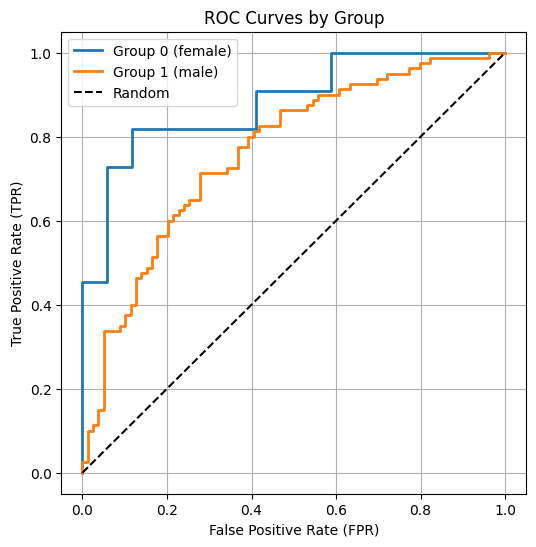

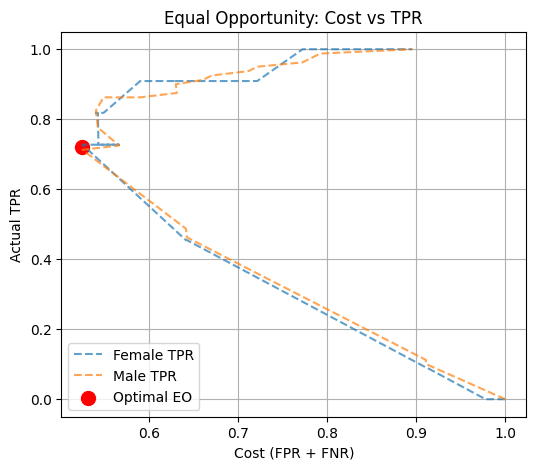

[EO] t0=0.553, t1=0.475, gap=0.015, acc=0.738, cost=0.525,  actual_tpr=0.720
Fold 5 | Acc=0.615 | Sens=0.540 | Spec=0.685 | TPR_gap=0.045 | FPR_gap=0.264 | DP_gap=0.205
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


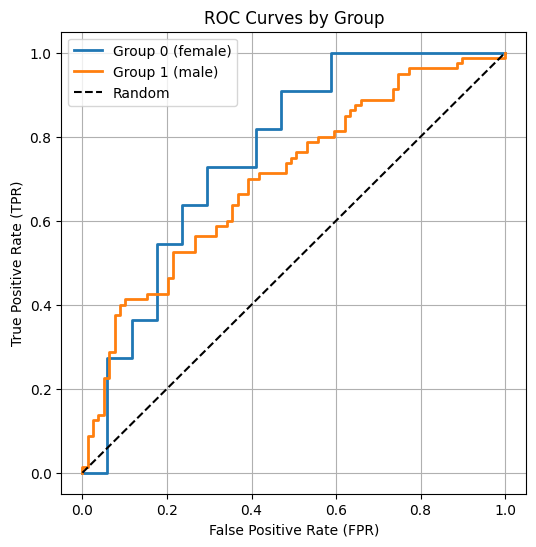

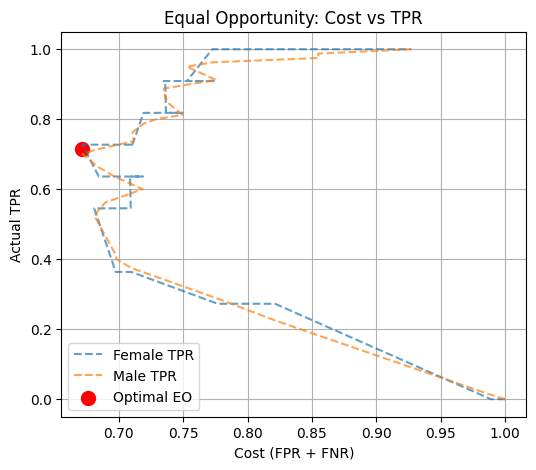

[EO] t0=0.382, t1=0.453, gap=0.027, acc=0.663, cost=0.672,  actual_tpr=0.714
Fold 6 | Acc=0.670 | Sens=0.706 | Spec=0.635 | TPR_gap=0.044 | FPR_gap=0.173 | DP_gap=0.157
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


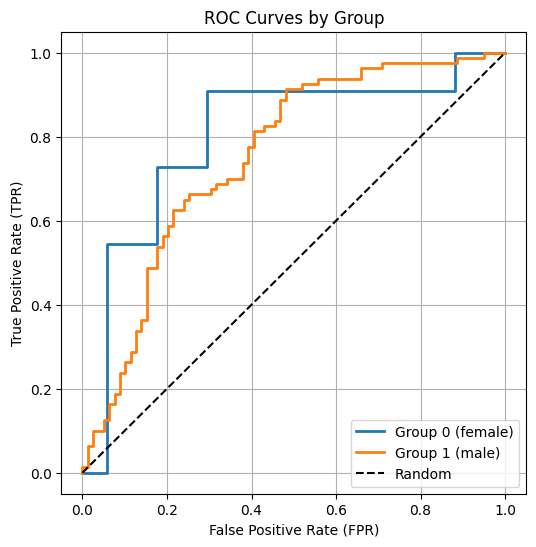

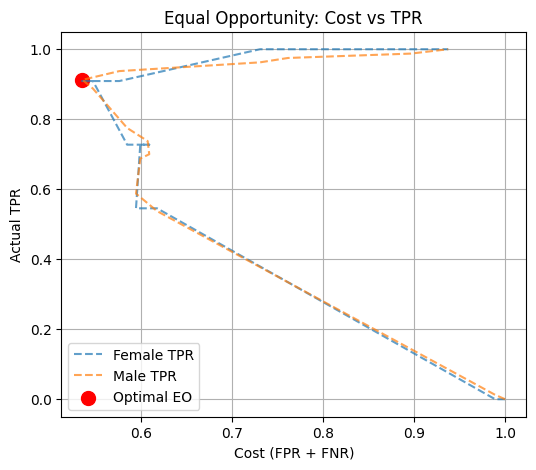

[EO] t0=0.379, t1=0.384, gap=0.003, acc=0.727, cost=0.536,  actual_tpr=0.911
Fold 7 | Acc=0.748 | Sens=0.902 | Spec=0.596 | TPR_gap=0.267 | FPR_gap=0.085 | DP_gap=0.215
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


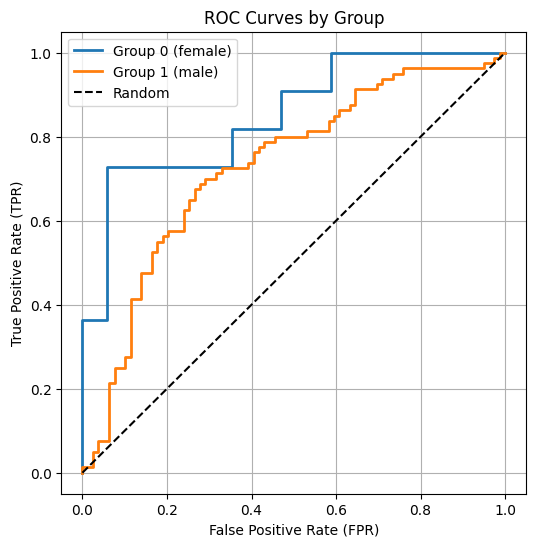

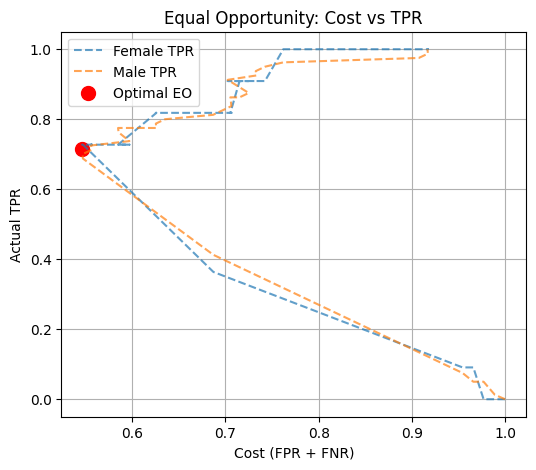

[EO] t0=0.597, t1=0.535, gap=0.027, acc=0.727, cost=0.547,  actual_tpr=0.714
Fold 8 | Acc=0.709 | Sens=0.804 | Spec=0.615 | TPR_gap=0.344 | FPR_gap=0.331 | DP_gap=0.381
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


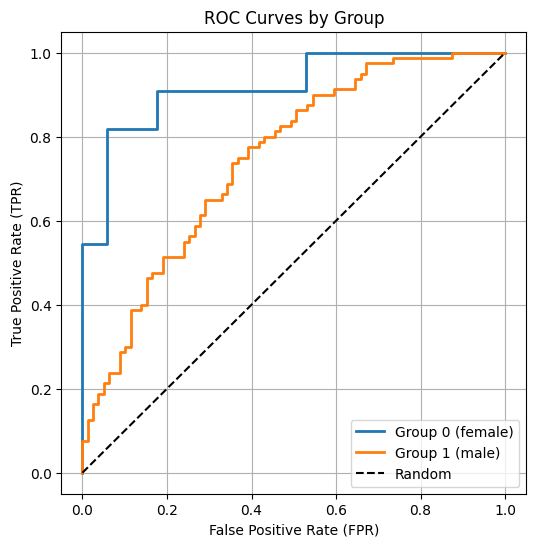

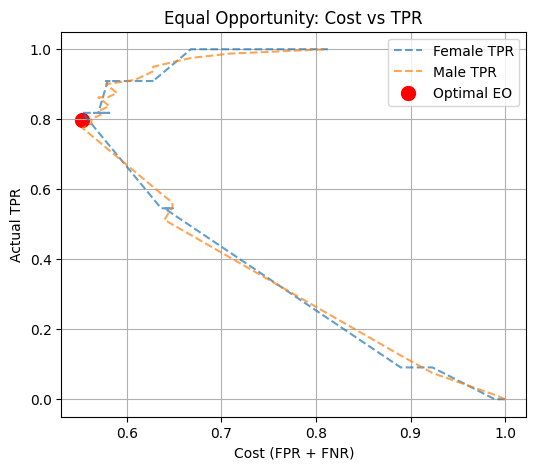

[EO] t0=0.474, t1=0.393, gap=0.043, acc=0.722, cost=0.553,  actual_tpr=0.797
Fold 9 | Acc=0.670 | Sens=0.667 | Spec=0.673 | TPR_gap=0.442 | FPR_gap=0.261 | DP_gap=0.364
Train:  745
Val:  187
Test:  103

--- Class distribution per group in validation set---
Group 0 (female):
  Total: 28
  Positives (Y=1): 11
  Negatives (Y=0): 17

Group 1 (male):
  Total: 159
  Positives (Y=1): 80
  Negatives (Y=0): 79


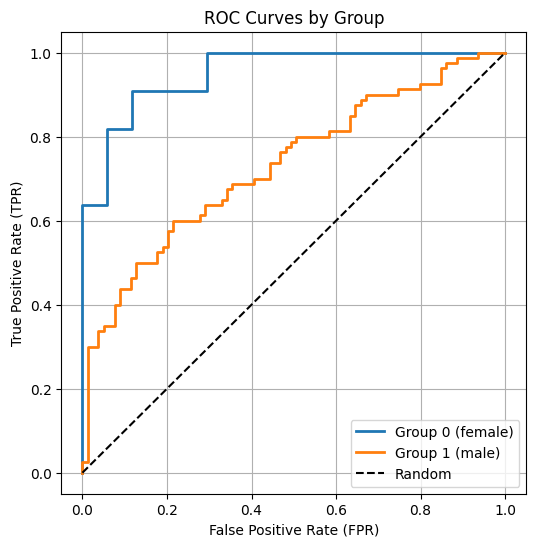

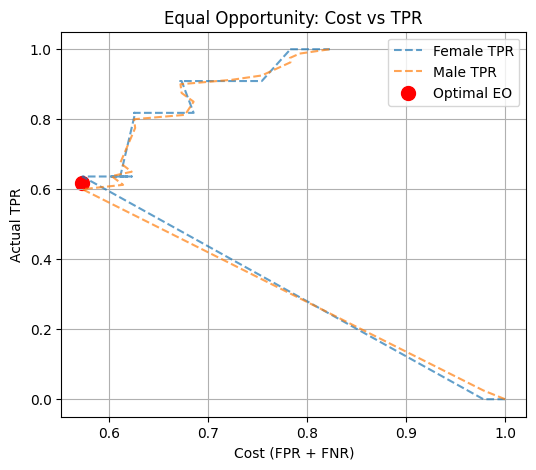

[EO] t0=0.605, t1=0.494, gap=0.036, acc=0.717, cost=0.573,  actual_tpr=0.618
Fold 10 | Acc=0.631 | Sens=0.569 | Spec=0.692 | TPR_gap=0.494 | FPR_gap=0.238 | DP_gap=0.369
performance (mean across folds):)
Accuracy: 0.6792569081404033
Std Accuracy: 0.04478687267991417
Sensitivity: 0.6847058823529413
Std Sensitivity: 0.10920311822641757
Specifity: 0.6730056980056981
Std Specifity: 0.044609246374892504

Fairness:
Mean TPR Gap: 0.2189105339105339
Std TPR Gap: 0.17011909149170815
Mean FPR Gap: 0.18969462062485318
Std FPR Gap: 0.08947641396497244
Mean DP Gap: 0.20490073145245558
Std DP Gap: 0.12806521224273112
1368.1056134700775


Final performance results averaged across repetitions:
Mean Accuracy across repetitions: 0.6744118745332337
Std Accuracy across repetitions: 0.009022655959097186
Mean Sensitivity across repetitions: 0.6997098039215686
Std Sensitivity across repetitions: 0.023498523516567362
Mean Specificity across repetitions: 0.6501282051282051
Std Specificity across repetitions: 0

In [86]:

if p_Method == "ASD-DiagNet" and p_mode == "whole":
    
    num_corr = len(all_corr[flist[0]][0])
    print("num_corr:  ",num_corr)
    
    start =time.time()
    batch_size = 8
    learning_rate_ae, learning_rate_clf = 0.0001, 0.0001
    num_epochs = 25

    p_bernoulli = None
    augmentation = p_augmentation
    use_dropout = False

    if not augmentation:
        eig_data = None

    aug_factor = 2
    num_neighbs = 5
    lim4sim = 2
    n_lat = int(num_corr/4)
    print(n_lat)
    start= time.time()

    print('p_bernoulli: ', p_bernoulli)
    print('augmentaiton: ', augmentation, 'aug_factor: ', aug_factor, 
          'num_neighbs: ', num_neighbs, 'lim4sim: ', lim4sim)
    print('use_dropout: ', use_dropout, '\n')


    sim_function = functools.partial(cal_similarity, lim=lim4sim)
    y_arr = np.array([get_label(f) for f in flist])
    flist = np.array(flist)
    kk=0 

    rep_mean_tpr = []
    rep_mean_fpr = []
    rep_mean_dp = []
    rep_mean_acc = []
    rep_mean_sens = []
    rep_mean_spec = []


    # store per-experiment stats
    exp_mean_acc, exp_std_acc = [], []
    exp_mean_sens, exp_std_sens = [], []
    exp_mean_spec, exp_std_spec = [], []

    exp_mean_tpr, exp_std_tpr = [], []
    exp_mean_fpr, exp_std_fpr = [], []
    exp_mean_dp,  exp_std_dp  = [], []

    for rp in range(num_repitition):
        crossval_res_kol=[]
        crossval_fairness = []
        kf = StratifiedKFold(n_splits=p_fold, random_state=rp, shuffle=True)
        y_arr = np.array([get_label(f) for f in flist])
        y_sensitive = np.array([get_sensitive(f) for f in flist])
        strat_labels = y_arr * 2 + y_sensitive # 0 -> female control, 1 -> male control, 2 -> female ASD, 3 -> male ASD
        for kk,(train_index, test_index) in enumerate(kf.split(flist, strat_labels)):
            train_samples, test_samples = flist[train_index], flist[test_index]

            if USE_THRESHOLD:
                # build stratification labels for train split
                train_sensitive = np.array([get_sensitive(f) for f in train_samples])
                train_labels = np.array([get_label(f) for f in train_samples])

                strat = train_labels * 2 + train_sensitive

                train_samples, val_samples = train_test_split(
                    train_samples, test_size=0.2, stratify=strat, random_state=42
                )

                print("Train: ", len(train_samples))
                print("Val: ",len(val_samples))
                print("Test: ", len(test_samples))




            verbose = (True if (kk == 0) else False)

            regions_inds = get_regs(train_samples,int(num_corr/4))

            num_inpp = len(regions_inds)
            n_lat = int(num_inpp/2)
            train_loader=get_loader(data=all_corr, samples_list=train_samples, 
                                    batch_size=batch_size, mode='train',
                                    augmentation=augmentation, aug_factor=aug_factor, 
                                    num_neighbs=num_neighbs, eig_data=eig_data, similarity_fn=sim_function, 
                                    verbose=verbose,regions=regions_inds)

            test_loader=get_loader(data=all_corr, samples_list=test_samples, 
                                   batch_size=batch_size, mode='test', augmentation=False, 
                                   verbose=verbose,regions=regions_inds)
            
            if USE_THRESHOLD:
                 val_loader=get_loader(data=all_corr, samples_list=val_samples, 
                                   batch_size=batch_size, mode='test', augmentation=False, 
                                   verbose=verbose,regions=regions_inds)

            model = MTAutoEncoder(tied=True, num_inputs=num_inpp, num_latent=n_lat, use_dropout=use_dropout)
            model.to(device)
            criterion_ae = nn.MSELoss(reduction='sum')
            criterion_clf = nn.BCEWithLogitsLoss()
            optimizer = optim.SGD([{'params': model.fc_encoder.parameters(), 'lr': learning_rate_ae},
                                   {'params': model.classifier.parameters(), 'lr': learning_rate_clf}],
                                  momentum=0.9)

            for epoch in range(1, num_epochs+1):
                if epoch <= 20:
                    train_losses = train(model, epoch, train_loader, p_bernoulli, mode='both')
                else:
                    train_losses = train(model, epoch, train_loader, p_bernoulli, mode='clf')

            if USE_THRESHOLD:
                #Validation
                y_val, prob_val, sens_val = test(model, criterion_ae, val_loader, eval_classifier=True)
                eo = learn_eo_thresholds(y_val, prob_val, sens_val)
                t0, t1 = eo["t0"], eo["t1"] 
                print(
                f"[EO] t0={t0:.3f}, t1={t1:.3f}, "
                f"gap={eo['gap']:.3f}, acc={eo['acc']:.3f}, cost={eo['cost']:.3f},  actual_tpr={eo['actual_tpr']:.3f}")

                #Test
                y_true, y_prob, sensitive = test(model, criterion_ae, test_loader, eval_classifier=True)
                y_pred_eo = apply_eo_thresholds(y_prob, sensitive, t0, t1)

                acc, sens, spec = confusion(y_true, y_pred_eo)
                crossval_res_kol.append([acc, sens, spec])

                delta_tpr, delta_fpr, delta_dp = compute_fairness_gaps(y_true, y_pred_eo, sensitive)
                crossval_fairness.append([delta_tpr, delta_fpr, delta_dp])
            else:
                acc, sens, spec, y_true, y_pred, sensitive = test(model, criterion_ae, test_loader, eval_classifier=True)
                crossval_res_kol.append([acc, sens, spec])

                delta_tpr, delta_fpr, delta_dp = compute_fairness_gaps(y_true, y_pred, sensitive)
                crossval_fairness.append([delta_tpr, delta_fpr, delta_dp])

            

            print( f"Fold {kk+1} | " f"Acc={acc:.3f} | " f"Sens={sens:.3f} | " f"Spec={spec:.3f} | " f"TPR_gap={delta_tpr:.3f} | " f"FPR_gap={delta_fpr:.3f} | " f"DP_gap={delta_dp:.3f}" )
        
        perf_arr = np.array(crossval_res_kol)
        fair_arr = np.array(crossval_fairness)

        print("performance (mean across folds):)")
        mean_acc_rp = perf_arr[:,0].mean()
        mean_sens_rp = perf_arr[:,1].mean()
        mean_spec_rp = perf_arr[:,2].mean()

        std_acc_rp = perf_arr[:,0].std()
        std_sens_rp = perf_arr[:,1].std()
        std_spec_rp = perf_arr[:,2].std()

        print("Accuracy:", mean_acc_rp)
        print("Std Accuracy:", std_acc_rp)
        print("Sensitivity:", mean_sens_rp)
        print("Std Sensitivity:", std_sens_rp)
        print("Specifity:", mean_spec_rp)
        print("Std Specifity:", std_spec_rp)

        rep_mean_acc.append(mean_acc_rp)
        rep_mean_sens.append(mean_sens_rp)
        rep_mean_spec.append(mean_spec_rp)

        print("\nFairness:")
        mean_tpr_rp = np.nanmean(fair_arr[:,0])
        mean_fpr_rp = np.nanmean(fair_arr[:,1])
        mean_dp_rp = np.nanmean(fair_arr[:,2])

        std_tpr_rp = np.nanstd(fair_arr[:,0])
        std_fpr_rp = np.nanstd(fair_arr[:,1])
        std_dp_rp = np.nanstd(fair_arr[:,2])

        print("Mean TPR Gap:", mean_tpr_rp)
        print("Std TPR Gap:", std_tpr_rp)

        print("Mean FPR Gap:", mean_fpr_rp)
        print("Std FPR Gap:", std_fpr_rp)

        print("Mean DP Gap:", mean_dp_rp)
        print("Std DP Gap:", std_dp_rp)
        
        rep_mean_tpr.append(mean_tpr_rp)
        rep_mean_fpr.append(mean_fpr_rp)
        rep_mean_dp.append(mean_dp_rp)

        # store per-experiment stats
        exp_mean_acc.append(mean_acc_rp)
        exp_std_acc.append(std_acc_rp)

        exp_mean_sens.append(mean_sens_rp)
        exp_std_sens.append(std_sens_rp)

        exp_mean_spec.append(mean_spec_rp)
        exp_std_spec.append(std_spec_rp)

        exp_mean_tpr.append(mean_tpr_rp)
        exp_std_tpr.append(std_tpr_rp)

        exp_mean_fpr.append(mean_fpr_rp)
        exp_std_fpr.append(std_fpr_rp)

        exp_mean_dp.append(mean_dp_rp)
        exp_std_dp.append(std_dp_rp)
        

        # print("averages:")
        # print(np.mean(np.array(crossval_res_kol),axis = 0))
        finish= time.time()

        print(finish-start)
    
    # final mean of repetition means:
    print("\n\nFinal performance results averaged across repetitions:")
    print("Mean Accuracy across repetitions:", np.mean(rep_mean_acc))
    print("Std Accuracy across repetitions:", np.std(rep_mean_acc))
    print("Mean Sensitivity across repetitions:", np.mean(rep_mean_sens))
    print("Std Sensitivity across repetitions:", np.std(rep_mean_sens))
    print("Mean Specificity across repetitions:", np.mean(rep_mean_spec))
    print("Std Specificity across repetitions:", np.std(rep_mean_spec))

    print("\n\nFinal fairness results averaged across repetitions:")
    print("Mean TPR Gap across repetitions:", np.mean(rep_mean_tpr))
    print("Std TPR Gap across repetitions:", np.std(rep_mean_tpr))
    print("Mean FPR Gap across repetitions:", np.mean(rep_mean_fpr))
    print("Std FPR Gap across repetitions:", np.std(rep_mean_fpr))
    print("Mean DP Gap across repetitions:", np.mean(rep_mean_dp))
    print("Std DP Gap across repetitions:", np.std(rep_mean_dp))

    #Create table for experiment stats
    rows = []

    for i in range(len(exp_mean_acc)):
        # Mean row
        rows.append([
            f"{i+1}: Mean",
            exp_mean_acc[i],
            exp_mean_sens[i],
            exp_mean_spec[i],
            exp_mean_tpr[i],
            exp_mean_fpr[i],
            exp_mean_dp[i]
        ])

        # Std row
        rows.append([
            f"{i+1}: Std",
            exp_std_acc[i],
            exp_std_sens[i],
            exp_std_spec[i],
            exp_std_tpr[i],
            exp_std_fpr[i],
            exp_std_dp[i]
        ])

    columns = [
        "Experiments",
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "TPR Gap",
        "FPR Gap",
        "Demographic Parity"
    ]

    # OVERALL MEAN
    overall_mean_row = [
        "Overall Mean",
        np.mean(exp_mean_acc),
        np.mean(exp_mean_sens),
        np.mean(exp_mean_spec),
        np.mean(exp_mean_tpr),
        np.mean(exp_mean_fpr),
        np.mean(exp_mean_dp)
    ]

    # OVERALL STD 
    overall_std_row = [
        "Overall Std",
        np.std(exp_mean_acc),
        np.std(exp_mean_sens),
        np.std(exp_mean_spec),
        np.std(exp_mean_tpr),
        np.std(exp_mean_fpr),
        np.std(exp_mean_dp)
    ]

    # Add to table
    rows.append(overall_mean_row)
    rows.append(overall_std_row)

    df = pd.DataFrame(rows, columns=columns)

    # clean formatting
    df = df.round(4)

    # save file
    df.to_csv("results/threshold-adjustment-ASD-DiagNet_fairness_results_full.csv", index=False)

    print("Excel saved: threshold-adjustment-ASD-DiagNet_fairness_results_full.xlsx")


In [ ]:

if p_Method == "ASD-DiagNet" and p_mode == "percenter":
    num_corr = len(all_corr[flist[0]][0])

    flist = os.listdir(data_main_path)

    for f in range(len(flist)):
        flist[f] = get_key(flist[f])
    
    centers_dict = {}
    for f in flist:
        key = f.split('_')[0]

        if key not in centers_dict:
            centers_dict[key] = []
        centers_dict[key].append(f)

    

    flist = np.array(centers_dict[p_center])
    
    start =time.time()
    #flist = np.array(sorted(os.listdir(data_main_path)))
    batch_size = 8
    learning_rate_ae, learning_rate_clf = 0.0001, 0.0001
    num_epochs = 25
    
    p_bernoulli = None
    augmentation = p_augmentation
    use_dropout = False

    aug_factor = 2
    num_neighbs = 5
    lim4sim = 2
    n_lat = int(num_corr/4)


    print('p_bernoulli: ', p_bernoulli)
    print('augmentation: ', augmentation, 'aug_factor: ', aug_factor, 
          'num_neighbs: ', num_neighbs, 'lim4sim: ', lim4sim)
    print('use_dropout: ', use_dropout, '\n')


    sim_function = functools.partial(cal_similarity, lim=lim4sim)
    all_rp_res=[]
    y_arr = np.array([get_label(f) for f in flist])

    kk=0 
    crossval_res_kol_kol=[]
    for rp in range(10):
        print("========================")
        crossval_res_kol = []
        start= time.time()
        kf = StratifiedKFold(n_splits=p_fold)
        #np.random.shuffle(flist)
        y_arr = np.array([get_label(f) for f in flist])
        for kk,(train_index, test_index) in enumerate(kf.split(flist, y_arr)):
        
            train_samples, test_samples = flist[train_index], flist[test_index]

            verbose = (True if (kk == 0) else False)

            regions_inds = get_regs(train_samples,int(num_corr/4))
            num_inpp = len(regions_inds)
            n_lat = int(num_inpp/2)
            num_inpp = len(regions_inds)
            train_loader=get_loader(data=all_corr, samples_list=train_samples, 
                                    batch_size=batch_size, mode='train',
                                    augmentation=augmentation, aug_factor=aug_factor, 
                                    num_neighbs=num_neighbs, eig_data=eig_data, similarity_fn=sim_function, 
                                    verbose=verbose,regions=regions_inds)

            test_loader=get_loader(data=all_corr, samples_list=test_samples, 
                                   batch_size=batch_size, mode='test', augmentation=False, 
                                   verbose=verbose,regions=regions_inds)

            model = MTAutoEncoder(tied=True, num_inputs=num_inpp, num_latent=n_lat, use_dropout=use_dropout)
            model.to(device)
            criterion_ae = nn.MSELoss(reduction='sum')
            criterion_clf = nn.BCEWithLogitsLoss()
            optimizer = optim.SGD([{'params': model.fc_encoder.parameters(), 'lr': learning_rate_ae},
                                   {'params': model.classifier.parameters(), 'lr': learning_rate_clf}],
                                  momentum=0.9)

            for epoch in range(1, num_epochs+1):
                if epoch <= 20:
                    train_losses = train(model, epoch, train_loader, p_bernoulli, mode='both')
                else:
                    train_losses = train(model, epoch, train_loader, p_bernoulli, mode='clf')


            res_mlp = test(model, criterion_ae, test_loader, eval_classifier=True)
            #print("fold",kk+1,":",test(model, criterion_ae, test_loader, eval_classifier=True))
            crossval_res_kol.append(res_mlp)
        print("Result of repeat ",rp,":")
        print(np.mean(np.array(crossval_res_kol),axis = 0))
        all_rp_res.append(np.mean(np.array(crossval_res_kol),axis = 0))
        finish= time.time()

        print("Running time:",finish-start)
    print("Avergae result of 10 repeats: ",np.mean(np.array(all_rp_res),axis = 0))

In [ ]:
if p_Method != "ASD-DiagNet" and p_mode == "whole":
    
    clf = SVC(gamma = 'auto') if  p_Method == 'SVM' else RandomForestClassifier(n_estimators=100)
    overall_result = []
    for rp in range(10):
        kf = StratifiedKFold(n_splits=p_fold, random_state=1, shuffle=True)
        np.random.shuffle(flist)
        y_arr = np.array([get_label(f) for f in flist])
        res = []
        for kk,(train_index, test_index) in enumerate(kf.split(flist, y_arr)):
            train_samples, test_samples = np.array(flist)[train_index], np.array(flist)[test_index]
            train_data = []
            train_labels = []
            test_data = []
            test_labels = []

            for i in train_samples:
                train_data.append(all_corr[i][0])
                train_labels.append(all_corr[i][1])

            for i in test_samples:
                test_data.append(all_corr[i][0])
                test_labels.append(all_corr[i][1])

            
            clf.fit(train_data,train_labels)
            pr = clf.predict(test_data)
            res.append(confusion(test_labels,pr))
        
        print("repeat: ",rp,np.mean(res, axis=0).tolist())
        overall_result.append(np.mean(res, axis=0).tolist())   
    print("---------------Result of repeating 10 times-------------------")
    print(np.mean(np.array(overall_result), axis=0).tolist())

In [ ]:
random.seed(19)
np.random.seed(19)
if p_Method != "ASD-DiagNet" and p_mode == "percenter":
    
    clf = SVC(gamma = 'auto') if  p_Method == 'SVM' else RandomForestClassifier(n_estimators=100)
    overall_result = []
    for rp in range(10):
        kf = StratifiedKFold(n_splits=p_fold, random_state=1, shuffle=True)
        np.random.shuffle(flist)
        y_arr = np.array([get_label(f) for f in flist])
        res = []
        for kk,(train_index, test_index) in enumerate(kf.split(flist, y_arr)):
            train_samples, test_samples = np.array(flist)[train_index], np.array(flist)[test_index]
            train_data = []
            train_labels = []
            test_data = []
            test_labels = []

            for i in train_samples:
                train_data.append(all_corr[i][0])
                train_labels.append(all_corr[i][1])

            for i in test_samples:
                test_data.append(all_corr[i][0])
                test_labels.append(all_corr[i][1])

            clf.fit(train_data,train_labels)
            pr = clf.predict(test_data)
            res.append(confusion(test_labels,pr))
        
        print("repeat: ",rp,np.mean(res, axis=0).tolist())
        overall_result.append(np.mean(res, axis=0).tolist())   
    print("---------------Result of repeating 10 times for: ",p_center,"-------------------")
    print(np.mean(np.array(overall_result), axis=0).tolist())